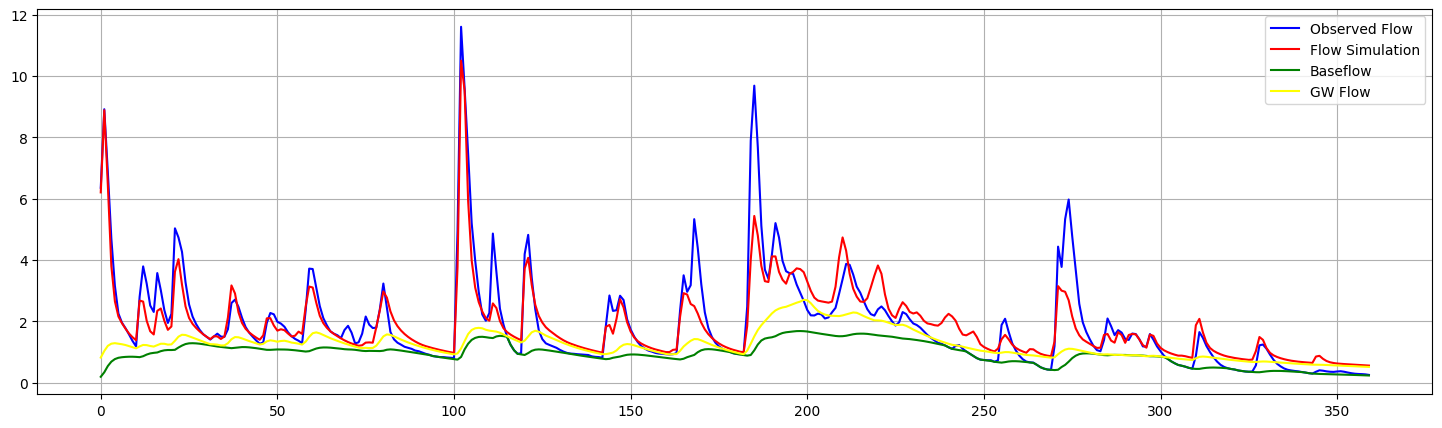

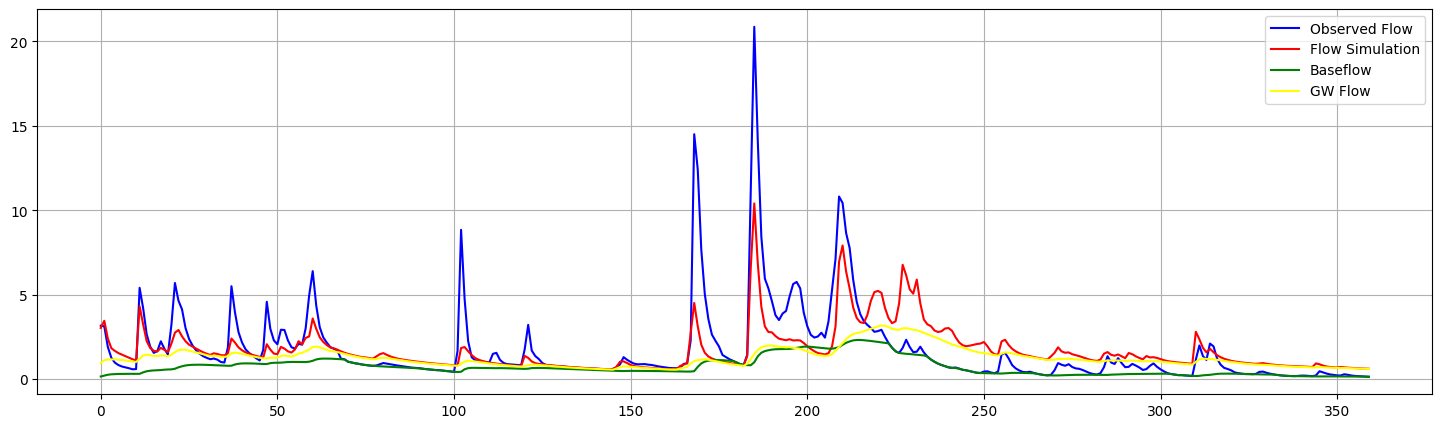

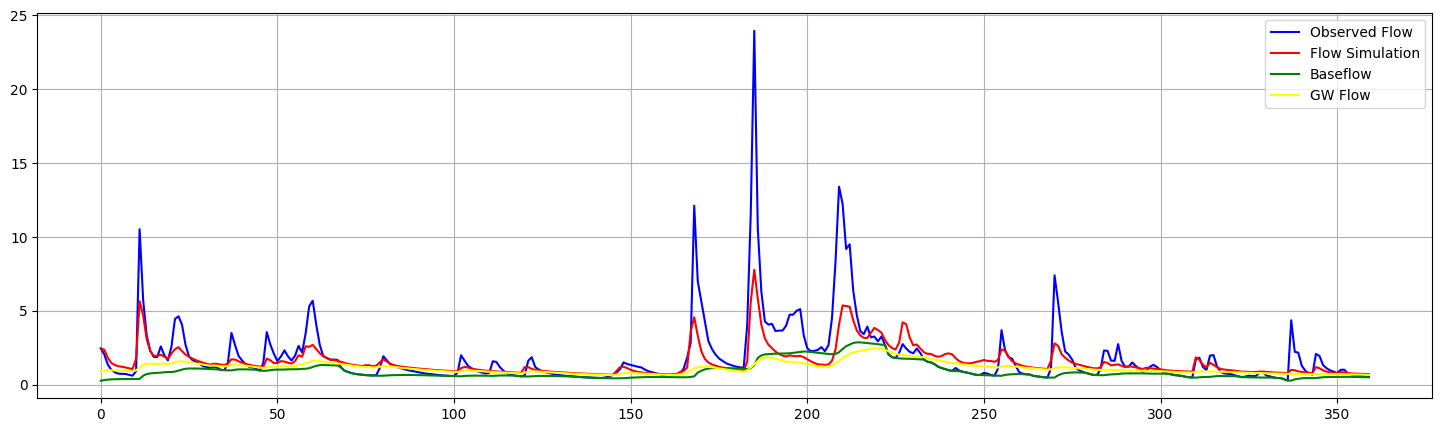

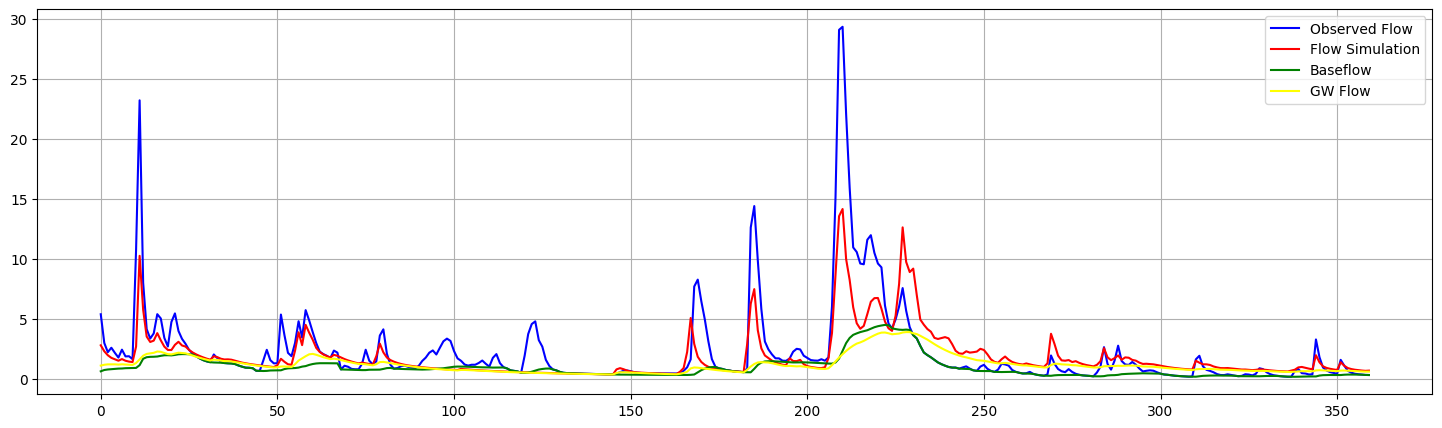

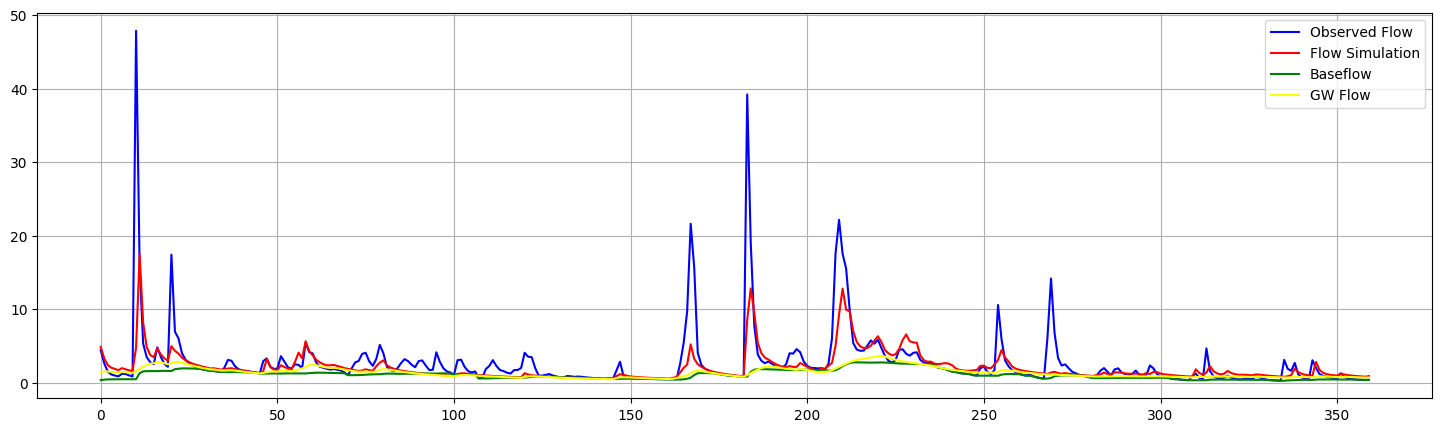

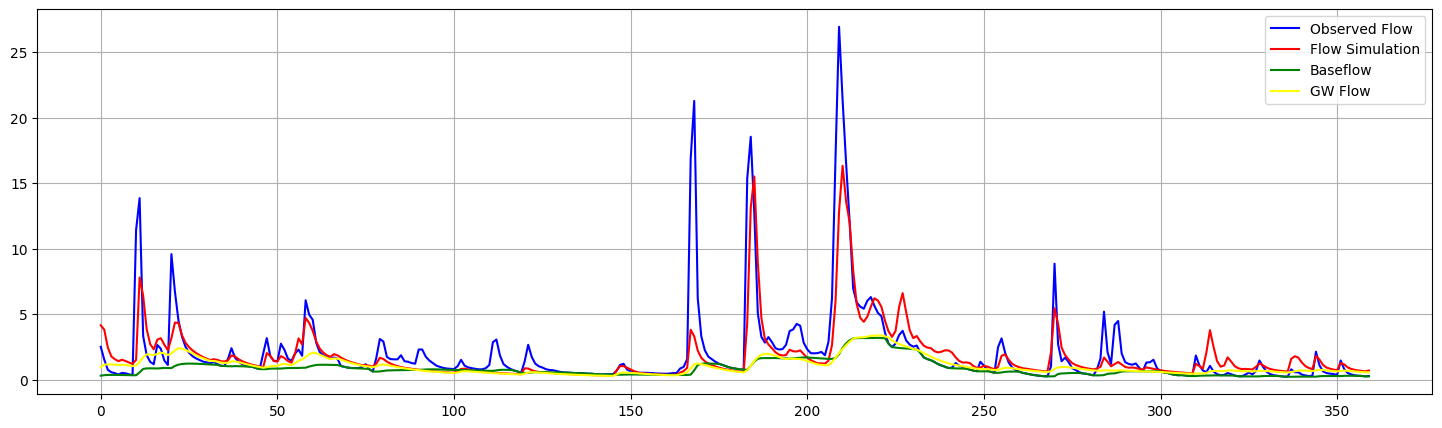

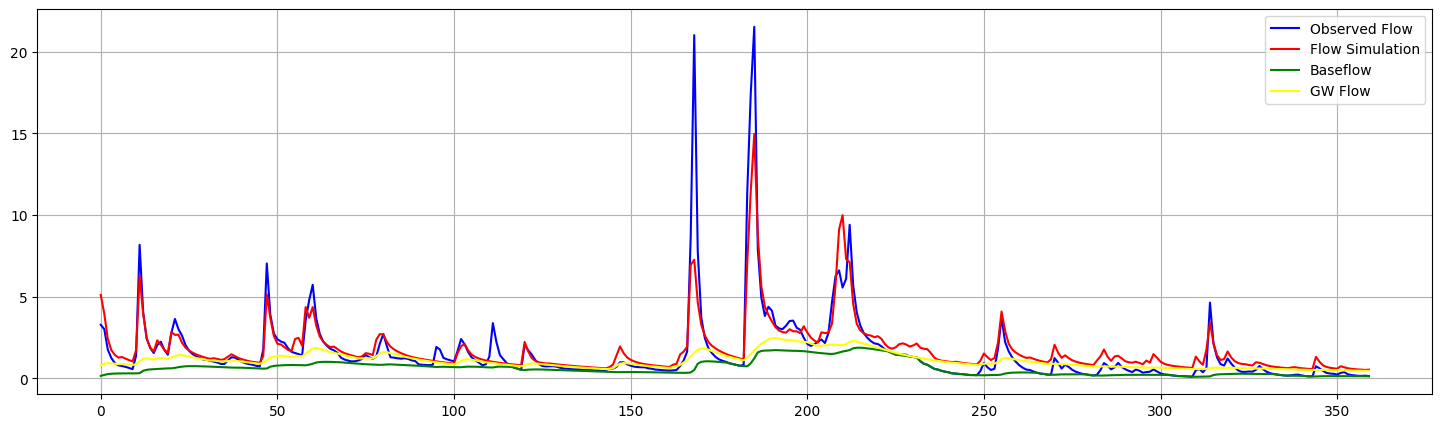

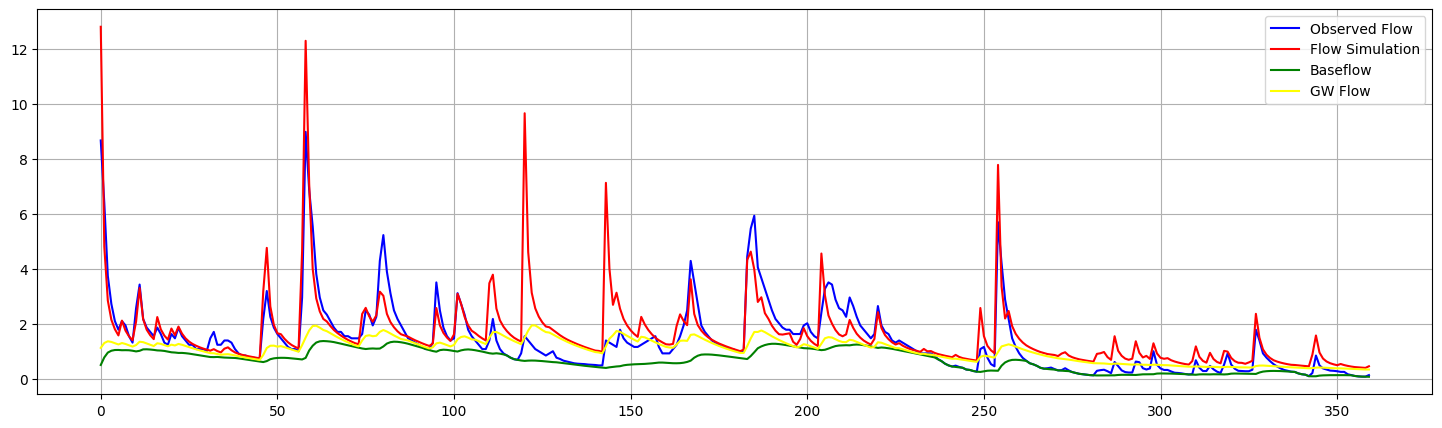

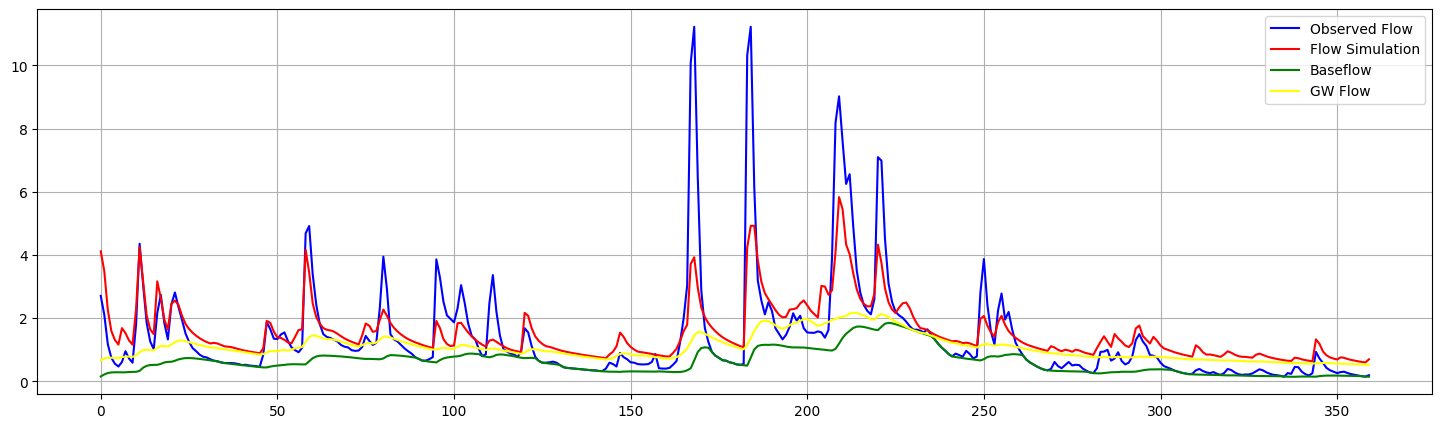

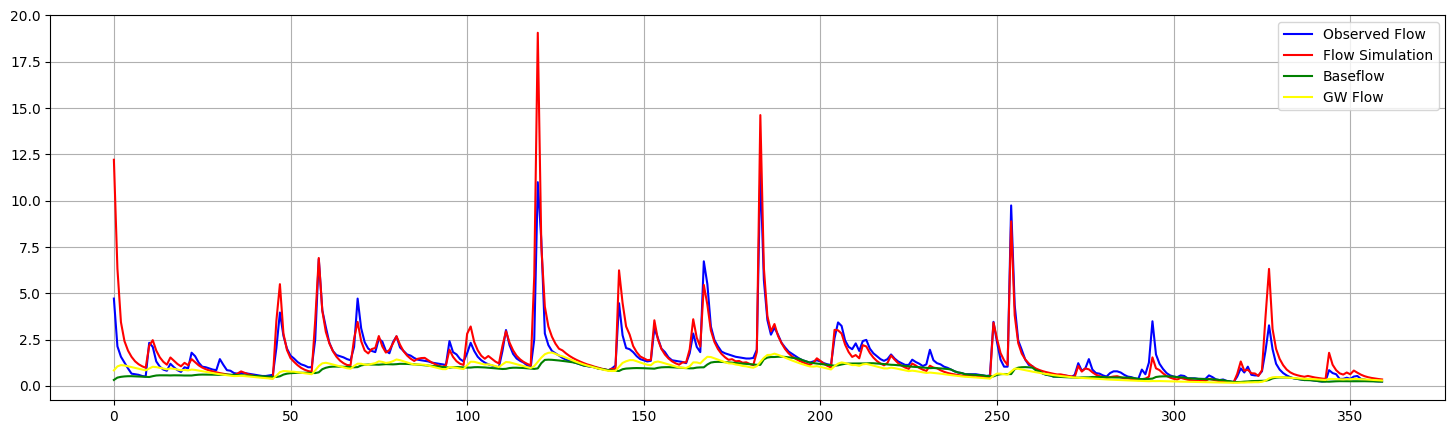

In [9]:
import numpy as np
import os
import matplotlib.pyplot as plt

obs= np.load("/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy")

sim= np.load("/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy")
sim= sim.squeeze()

baseflow= np.load("/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy")

gwflow= np.load("/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy")
gwflow= gwflow.squeeze()

# for i in range(obs.shape[1]):
for i in range(10):
    plt.figure(figsize=(18,5))

    plt.plot(obs[360:720,i], color='blue', label= 'Observed Flow')
    plt.plot(sim[360:720,i], color= 'red', label='Flow Simulation')
    plt.plot(baseflow[360:720,i], color='green', label='Baseflow')
    plt.plot(gwflow[360:720,i], color='yellow', label= 'GW Flow')

    plt.grid()
    plt.legend()
    plt.show()
    


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

method= 'Furey'
methods= ['Furey', 'USGS', 'Eckhardt']

for method in methods:

    # model= 'HBV'
    models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

    for model in models:
        print(method, model)

        if model=='HBV':
            dyn= 'parBETA_parBETAET_'

        if model=='marrmot_PRMS':
            dyn= 'alpha_cgw_scx_tt_'

        if model=='HBV_capillary':
            dyn= 'parBETA_parBETAET_parK0_parUZL_'
        # ==========================================================
        # SETTINGS
        # ==========================================================
        base_dir = f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi"

        model_dir = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999"
        )

        regions = [f"Region_{i}" for i in range(1, 8)]


        # ==========================================================
        # FUNCTION
        # ==========================================================
        def find_best_lag(flow, bf, max_lag=30):
            """
            Lag maximizing Pearson correlation between
            flow(t) and bf(t+lag).
            """

            flow = np.asarray(flow, dtype=float)
            bf = np.asarray(bf, dtype=float)

            mask = np.isfinite(flow) & np.isfinite(bf)
            flow = flow[mask]
            bf = bf[mask]

            if len(flow) < max_lag + 10:
                return np.nan

            best_corr = -np.inf
            best_lag = np.nan

            for lag in range(max_lag + 1):

                if lag == 0:
                    x = flow
                    y = bf
                else:
                    x = flow[:-lag]
                    y = bf[lag:]

                if len(x) < 10:
                    continue

                x = x - np.mean(x)
                y = y - np.mean(y)

                sx = np.std(x)
                sy = np.std(y)

                if sx == 0 or sy == 0:
                    continue

                corr = np.mean((x / sx) * (y / sy))

                if corr > best_corr:
                    best_corr = corr
                    best_lag = lag

            return best_lag


        # ==========================================================
        # LOOP OVER REGIONS
        # ==========================================================
        print("=" * 90)
        print(
            f"{'Region':<10}"
            f"{'Obs Mean':>10}"
            f"{'Obs Median':>12}"
            f"{'Sim Mean':>12}"
            f"{'Sim Median':>12}"
        )
        print("=" * 90)

        all_obs_lags = []
        all_sim_lags = []

        for region in regions:

            folder = os.path.join(base_dir, region, model_dir)

            obs = np.load(os.path.join(folder, "00060_Mean.npy"))
            sim = np.load(os.path.join(folder, "flow_sim.npy")).squeeze()

            baseflow = np.load(os.path.join(folder, "baseflow.npy"))
            gwflow = np.load(os.path.join(folder, "gwflow.npy")).squeeze()

            nbasins = obs.shape[1]

            obs_lags = np.full(nbasins, np.nan)
            sim_lags = np.full(nbasins, np.nan)

            for b in range(nbasins):

                obs_lags[b] = find_best_lag(
                    obs[:, b],
                    baseflow[:, b],
                    max_lag=30,
                )

                sim_lags[b] = find_best_lag(
                    sim[:, b],
                    gwflow[:, b],
                    max_lag=30,
                )

            all_obs_lags.extend(obs_lags[np.isfinite(obs_lags)])
            all_sim_lags.extend(sim_lags[np.isfinite(sim_lags)])

            print(
                f"{region:<10}"
                f"{np.nanmean(obs_lags):>10.2f}"
                f"{np.nanmedian(obs_lags):>12.2f}"
                f"{np.nanmean(sim_lags):>12.2f}"
                f"{np.nanmedian(sim_lags):>12.2f}"
            )

        print("=" * 90)
        print(
            f"{'Overall':<10}"
            f"{np.nanmean(all_obs_lags):>10.2f}"
            f"{np.nanmedian(all_obs_lags):>12.2f}"
            f"{np.nanmean(all_sim_lags):>12.2f}"
            f"{np.nanmedian(all_sim_lags):>12.2f}"
        )
        print("=" * 90)


        # # ==========================================================
        # # OPTIONAL: OVERALL HISTOGRAM
        # # ==========================================================
        # plt.figure(figsize=(8, 5))

        # bins = np.arange(-0.5, 31.5, 1)

        # plt.hist(all_obs_lags, bins=bins, alpha=0.6, label="Observation")
        # plt.hist(all_sim_lags, bins=bins, alpha=0.6, label="Simulation")

        # plt.xlabel("Lag (days)")
        # plt.ylabel("Number of basins")
        # plt.title("Flow-Baseflow Lag (0-30 days)")
        # plt.legend()
        # plt.tight_layout()
        # plt.show()

Furey HBV
Region      Obs Mean  Obs Median    Sim Mean  Sim Median
Region_1        3.91        4.00        2.32        2.00
Region_2        3.19        3.00        3.26        3.00
Region_3        3.32        3.00        2.12        2.00
Region_4        3.51        3.00        2.80        2.00
Region_5        2.78        2.00        2.35        2.00
Region_6        4.45        4.00        4.88        4.00
Region_7        4.67        5.00        5.22        5.00
Overall         3.66        3.00        3.19        3.00
Furey marrmot_PRMS
Region      Obs Mean  Obs Median    Sim Mean  Sim Median
Region_1        3.91        4.00        2.39        2.00
Region_2        3.19        3.00        3.08        3.00
Region_3        3.32        3.00        2.48        2.00
Region_4        3.51        3.00        3.76        3.00
Region_5        2.78        2.00        2.13        2.00
Region_6        4.45        4.00        4.22        4.00
Region_7        4.67        5.00        3.31        3.00
Ov

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import os

method= 'Furey'
methods= ['Furey', 'USGS', 'Eckhardt']

for method in methods:

    # model= 'HBV'
    models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

    for model in models:
        print(method, model)

        if model=='HBV':
            dyn= 'parBETA_parBETAET_'

        if model=='marrmot_PRMS':
            dyn= 'alpha_cgw_scx_tt_'

        if model=='HBV_capillary':
            dyn= 'parBETA_parBETAET_parK0_parUZL_'
        # ==========================================================
        # SETTINGS
        # ==========================================================
        base_dir = f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single"

        model_dir = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999"
        )

        regions = [f"Region_{i}" for i in range(1, 8)]


        # ==========================================================
        # FUNCTION
        # ==========================================================
        def find_best_lag(flow, bf, max_lag=30):
            """
            Lag maximizing Pearson correlation between
            flow(t) and bf(t+lag).
            """

            flow = np.asarray(flow, dtype=float)
            bf = np.asarray(bf, dtype=float)

            mask = np.isfinite(flow) & np.isfinite(bf)
            flow = flow[mask]
            bf = bf[mask]

            if len(flow) < max_lag + 10:
                return np.nan

            best_corr = -np.inf
            best_lag = np.nan

            for lag in range(max_lag + 1):

                if lag == 0:
                    x = flow
                    y = bf
                else:
                    x = flow[:-lag]
                    y = bf[lag:]

                if len(x) < 10:
                    continue

                x = x - np.mean(x)
                y = y - np.mean(y)

                sx = np.std(x)
                sy = np.std(y)

                if sx == 0 or sy == 0:
                    continue

                corr = np.mean((x / sx) * (y / sy))

                if corr > best_corr:
                    best_corr = corr
                    best_lag = lag

            return best_lag


        # ==========================================================
        # LOOP OVER REGIONS
        # ==========================================================
        print("=" * 90)
        print(
            f"{'Region':<10}"
            f"{'Obs Mean':>10}"
            f"{'Obs Median':>12}"
            f"{'Sim Mean':>12}"
            f"{'Sim Median':>12}"
        )
        print("=" * 90)

        all_obs_lags = []
        all_sim_lags = []

        for region in regions:

            folder = os.path.join(base_dir, region, model_dir)

            obs = np.load(os.path.join(folder, "00060_Mean.npy"))
            sim = np.load(os.path.join(folder, "flow_sim.npy")).squeeze()

            baseflow = np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy")
            gwflow = np.load(os.path.join(folder, "gwflow.npy")).squeeze()
            single= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy")
            multi= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/{region}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy")
            nbasins = obs.shape[1]

            obs_lags = np.full(nbasins, np.nan)
            sim_lags = np.full(nbasins, np.nan)

            for b in range(nbasins):

                obs_lags[b] = find_best_lag(
                    baseflow[:, b],
                    single[:, b],
                    max_lag=30,
                )

                sim_lags[b] = find_best_lag(
                    baseflow[:, b],
                    multi[:, b],
                    max_lag=30,
                )

            all_obs_lags.extend(obs_lags[np.isfinite(obs_lags)])
            all_sim_lags.extend(sim_lags[np.isfinite(sim_lags)])

            print(
                f"{region:<10}"
                f"{np.nanmean(obs_lags):>10.2f}"
                f"{np.nanmedian(obs_lags):>12.2f}"
                f"{np.nanmean(sim_lags):>12.2f}"
                f"{np.nanmedian(sim_lags):>12.2f}"
            )

        print("=" * 90)
        print(
            f"{'Overall':<10}"
            f"{np.nanmean(all_obs_lags):>10.2f}"
            f"{np.nanmedian(all_obs_lags):>12.2f}"
            f"{np.nanmean(all_sim_lags):>12.2f}"
            f"{np.nanmedian(all_sim_lags):>12.2f}"
        )
        print("=" * 90)


        # # ==========================================================
        # # OPTIONAL: OVERALL HISTOGRAM
        # # ==========================================================
        # plt.figure(figsize=(8, 5))

        # bins = np.arange(-0.5, 31.5, 1)

        # plt.hist(all_obs_lags, bins=bins, alpha=0.6, label="Observation")
        # plt.hist(all_sim_lags, bins=bins, alpha=0.6, label="Simulation")

        # plt.xlabel("Lag (days)")
        # plt.ylabel("Number of basins")
        # plt.title("Flow-Baseflow Lag (0-30 days)")
        # plt.legend()
        # plt.tight_layout()
        # plt.show()
        print('SINGLE')

Furey HBV
Region      Obs Mean  Obs Median    Sim Mean  Sim Median


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

In [11]:
import os
import numpy as np

# ==========================================================
# SETTINGS
# ==========================================================
methods= ['Furey', 'USGS', 'Eckhardt', 'LocalHYSEP']



    # model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


regions = [f"Region_{i}" for i in range(1, 8)]


# ==========================================================
# FUNCTIONS
# ==========================================================
def find_best_lag_rmse_high_total_flow(
    total_flow,
    baseflow,
    gwflow,
    max_lag=30,
    percentile=50
):
    """
    Finds the lag that minimizes RMSE between observed baseflow
    and modeled groundwater flow, evaluated only on high total-flow
    days.

    Lag convention:
        lag > 0 means gwflow(t + lag) is compared with
        baseflow(t).

    Parameters
    ----------
    total_flow : array-like
        Observed total streamflow, used to identify high-flow days.

    baseflow : array-like
        Observed baseflow.

    gwflow : array-like
        Modeled groundwater flow.

    max_lag : int
        Maximum lag to test, in days.

    percentile : float
        Percentile of total flow used as the high-flow threshold.

    Returns
    -------
    best_lag : float
        Lag corresponding to minimum RMSE.
    """

    total_flow = np.asarray(total_flow, dtype=float)
    baseflow = np.asarray(baseflow, dtype=float)
    gwflow = np.asarray(gwflow, dtype=float)

    # ------------------------------------------------------
    # Remove invalid values while preserving time alignment
    # ------------------------------------------------------

    mask = (
        np.isfinite(total_flow)
        & np.isfinite(baseflow)
        & np.isfinite(gwflow)
    )

    total_flow = total_flow[mask]
    baseflow = baseflow[mask]
    gwflow = gwflow[mask]

    if len(baseflow) < max_lag + 10:
        return np.nan

    # ------------------------------------------------------
    # Define high total-flow threshold
    # ------------------------------------------------------

    threshold = np.percentile(total_flow, percentile)

    best_rmse = np.inf
    best_lag = np.nan

    # ------------------------------------------------------
    # Search lag
    # ------------------------------------------------------

    for lag in range(max_lag + 1):

        if lag == 0:

            bf = baseflow
            gw = gwflow
            tf = total_flow

        else:

            # baseflow(t) vs gwflow(t + lag)
            bf = baseflow[:-lag]
            gw = gwflow[lag:]

            # Total flow corresponding to baseflow(t)
            tf = total_flow[:-lag]

        # --------------------------------------------------
        # Select only high TOTAL FLOW days
        # --------------------------------------------------

        high_flow = tf > threshold

        bf_high = bf[high_flow]
        gw_high = gw[high_flow]

        if len(bf_high) < 10:
            continue

        # --------------------------------------------------
        # RMSE between baseflow and gwflow
        # --------------------------------------------------

        rmse = np.sqrt(
            np.mean((bf_high - gw_high) ** 2)
        )

        if rmse < best_rmse:
            best_rmse = rmse
            best_lag = lag

    return best_lag


def find_best_lag_rmse_highflow(x, y, max_lag=30, percentile=50):
    """
    Finds lag minimizing RMSE only during high-flow periods,
    defined by observed baseflow above a percentile threshold.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    threshold = np.percentile(x, percentile)

    best_rmse = np.inf
    best_lag = np.nan

    for lag in range(max_lag + 1):

        if lag == 0:
            xx = x
            yy = y
        else:
            xx = x[:-lag]
            yy = y[lag:]

        # Only high observed-baseflow periods
        high = xx > threshold

        xx = xx[high]
        yy = yy[high]

        if len(xx) < 10:
            continue

        rmse = np.sqrt(np.mean((xx - yy) ** 2))

        if rmse < best_rmse:
            best_rmse = rmse
            best_lag = lag

    return best_lag

def find_best_lag_rmse(x, y, max_lag=30):
    """
    Returns the lag that minimizes RMSE between
    x(t) and y(t + lag).
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # Remove NaNs / infs
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if len(x) < max_lag + 10:
        return np.nan

    best_rmse = np.inf
    best_lag = np.nan

    for lag in range(max_lag + 1):

        if lag == 0:
            xx = x
            yy = y
        else:
            xx = x[:-lag]
            yy = y[lag:]

        if len(xx) < 10:
            continue

        # RMSE
        rmse = np.sqrt(np.mean((xx - yy) ** 2))

        if rmse < best_rmse:
            best_rmse = rmse
            best_lag = lag

    return best_lag

def find_best_lag(x, y, max_lag=30):
    """
    Returns the lag that maximizes the Pearson correlation
    between x(t) and y(t + lag).
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if len(x) < max_lag + 10:
        return np.nan

    best_corr = -np.inf
    best_lag = np.nan

    for lag in range(max_lag + 1):

        if lag == 0:
            xx = x
            yy = y
        else:
            xx = x[:-lag]
            yy = y[lag:]

        if len(xx) < 10:
            continue

        xx = xx - xx.mean()
        yy = yy - yy.mean()

        sx = xx.std()
        sy = yy.std()

        if sx == 0 or sy == 0:
            continue

        corr = np.mean((xx / sx) * (yy / sy))

        if corr > best_corr:
            best_corr = corr
            best_lag = lag

    return best_lag


# ==========================================================
# MAIN LOOP
# ==========================================================

for method in methods:

    for model in models:
        BASE_DIR = "/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single"
        MULTI_DIR = f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi"

        methods = ["Furey", "USGS", "Eckhardt"]
        models = ["HBV", "marrmot_PRMS", "HBV_capillary"]

        dyn_map = {
            "HBV": "parBETA_parBETAET_",
            "marrmot_PRMS": "alpha_cgw_scx_tt_",
            "HBV_capillary": "parBETA_parBETAET_parK0_parUZL_",
        }

        dyn = dyn_map[model]

        model_dir = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999"
        )

        print(f"\nMethod : {method}")
        print(f"Model  : {model}")

        print("=" * 90)
        print(
            f"{'Region':<10}"
            f"{'Single Mean':>14}"
            f"{'Single Med':>14}"
            f"{'Multi Mean':>14}"
            f"{'Multi Med':>14}"
        )
        print("=" * 90)

        all_single = []
        all_multi = []

        for region in regions:

            single_folder = os.path.join(BASE_DIR, region, model_dir)
            multi_folder = os.path.join(MULTI_DIR, region, model_dir)


            obs_flow = np.load(
                os.path.join(multi_folder, "00060_Mean.npy")).squeeze()

            baseflow = np.load(os.path.join(multi_folder, "baseflow.npy"))

            single_gw = np.load(
                os.path.join(single_folder, "gwflow.npy")
            ).squeeze()

            multi_gw = np.load(
                os.path.join(multi_folder, "gwflow.npy")
            ).squeeze()

            nbasins = baseflow.shape[1]

            single_lags = np.full(nbasins, np.nan)
            multi_lags = np.full(nbasins, np.nan)

            for b in range(nbasins):

                threshold = np.median(baseflow[:,b])
                # threshold, np.mean(obs)
                
                low = baseflow[:,b] <= threshold
                high = baseflow[:,b] > threshold


                single_lags[b] = find_best_lag_rmse_high_total_flow(
                    obs_flow[:, b],
                    baseflow[:, b],
                    single_gw[:, b],
                    max_lag=30,
                    percentile=50
                )

                multi_lags[b] = find_best_lag_rmse_high_total_flow(
                    obs_flow[:, b],
                    baseflow[:, b],
                    multi_gw[:, b],
                    max_lag=30,
                    percentile=50
                )

            all_single.extend(single_lags[np.isfinite(single_lags)])
            all_multi.extend(multi_lags[np.isfinite(multi_lags)])

            print(
                f"{region:<10}"
                f"{np.nanmean(single_lags):>14.2f}"
                f"{np.nanmedian(single_lags):>14.2f}"
                f"{np.nanmean(multi_lags):>14.2f}"
                f"{np.nanmedian(multi_lags):>14.2f}"
            )

        print("=" * 90)
        print(
            f"{'Overall':<10}"
            f"{np.nanmean(all_single):>14.2f}"
            f"{np.nanmedian(all_single):>14.2f}"
            f"{np.nanmean(all_multi):>14.2f}"
            f"{np.nanmedian(all_multi):>14.2f}"
        )
        print("=" * 90)


Method : Furey
Model  : HBV
Region       Single Mean    Single Med    Multi Mean     Multi Med
Region_1            0.00          0.00          0.03          0.00
Region_2            0.81          0.00          0.21          0.00
Region_3            0.97          0.00          0.09          0.00
Region_4            3.10          0.00          1.37          0.00
Region_5            1.66          0.00          2.35          0.00
Region_6            3.50          0.00          4.72          0.00
Region_7            0.35          0.00          1.31          0.00
Overall             1.27          0.00          1.20          0.00

Method : Furey
Model  : marrmot_PRMS
Region       Single Mean    Single Med    Multi Mean     Multi Med
Region_1            0.40          0.00          0.11          0.00
Region_2            0.41          0.00          0.58          0.00
Region_3            7.89          0.00          0.65          0.00
Region_4            3.22          0.00          2.98          

Mean Lag (Single):0.0
Mean Lag (Multi):0.0


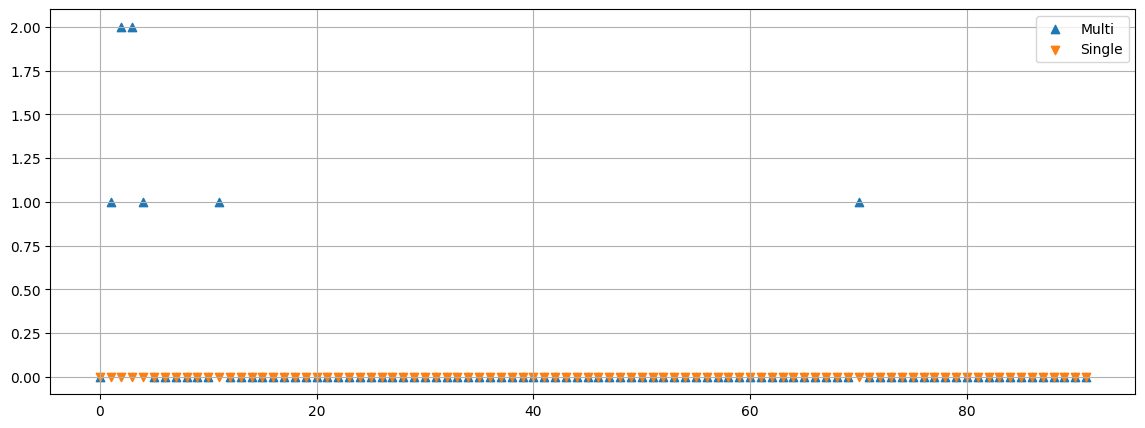

Mean Lag (Single):0.0
Mean Lag (Multi):0.0


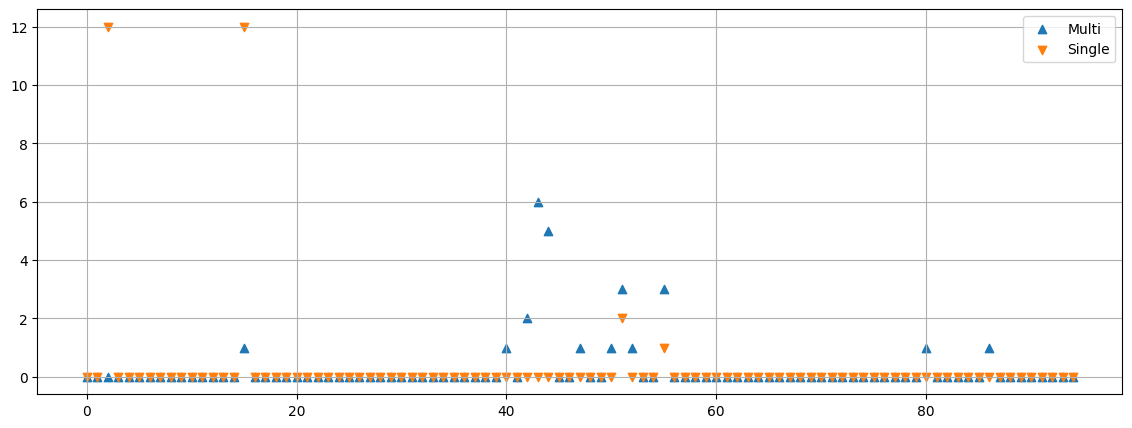

Mean Lag (Single):0.0
Mean Lag (Multi):0.0


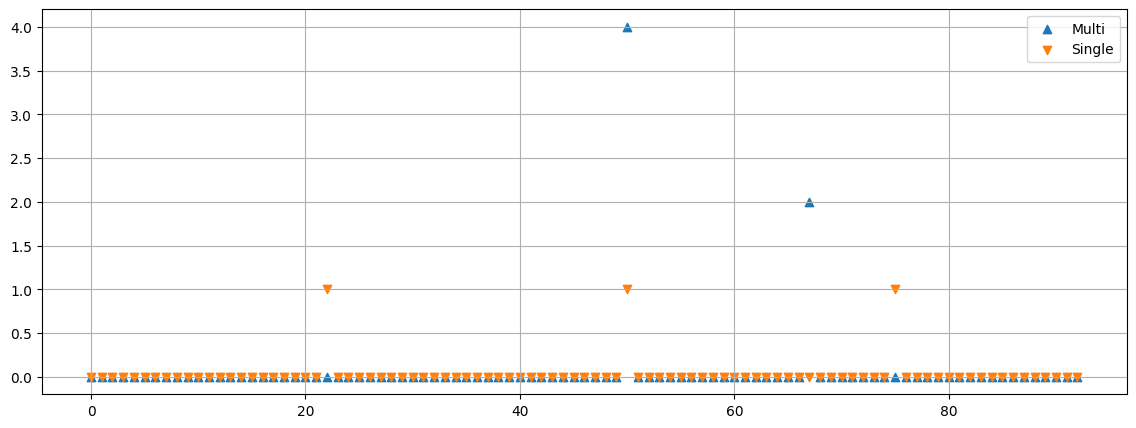

Mean Lag (Single):0.0
Mean Lag (Multi):0.0


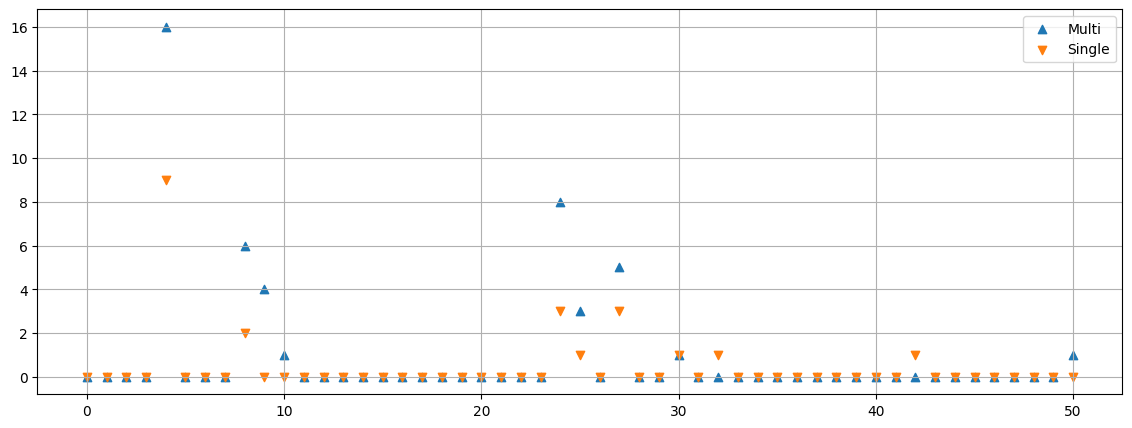

Mean Lag (Single):0.0
Mean Lag (Multi):0.0


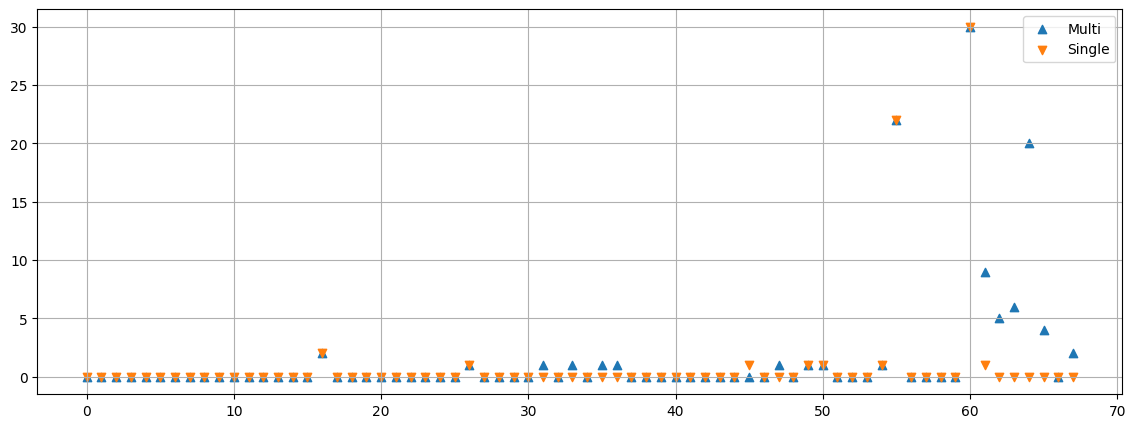

Mean Lag (Single):0.0
Mean Lag (Multi):0.0


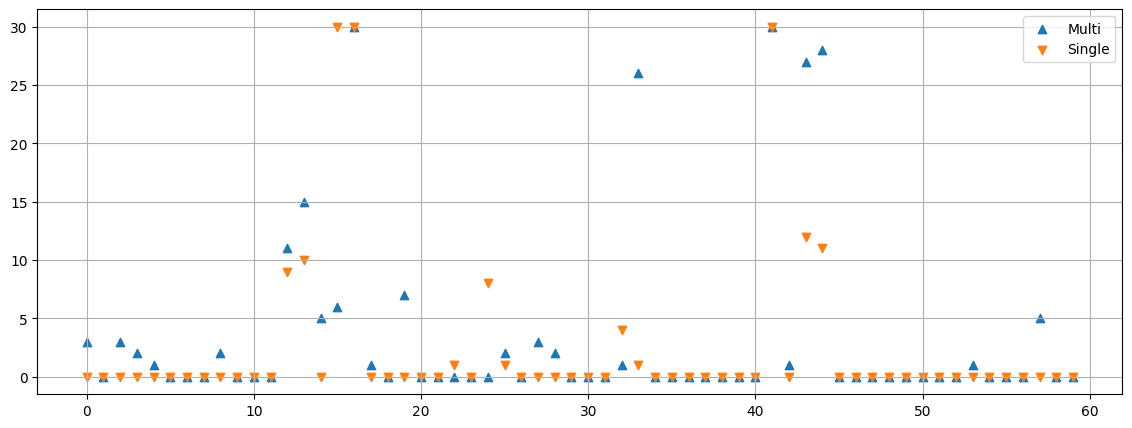

Mean Lag (Single):0.0
Mean Lag (Multi):0.0


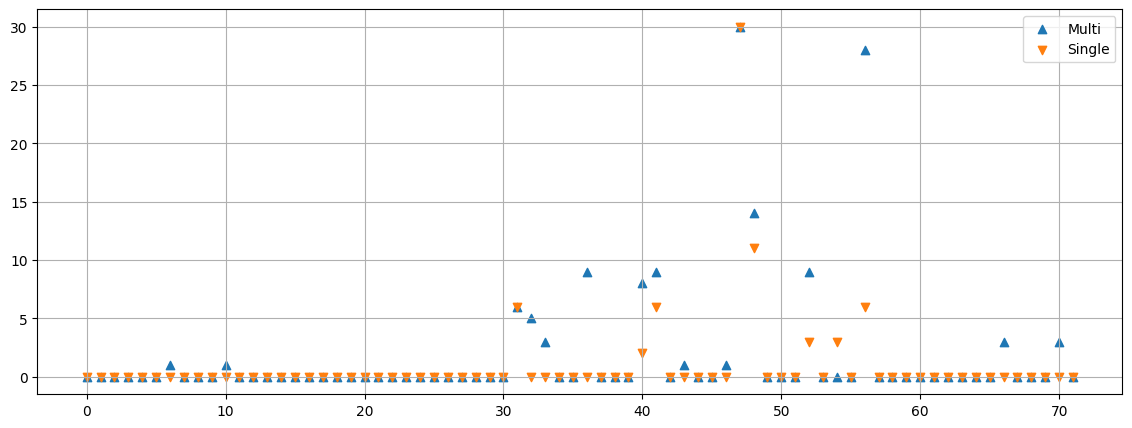

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
def find_best_lag_rmse(x, y, max_lag=30):
    """
    Returns the lag that minimizes RMSE between
    x(t) and y(t + lag).
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # Remove NaNs / infs
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if len(x) < max_lag + 10:
        return np.nan

    best_rmse = np.inf
    best_lag = np.nan

    for lag in range(max_lag + 1):

        if lag == 0:
            xx = x
            yy = y
        else:
            xx = x[:-lag]
            yy = y[lag:]

        if len(xx) < 10:
            continue

        # RMSE
        rmse = np.sqrt(np.mean((xx - yy) ** 2))

        if rmse < best_rmse:
            best_rmse = rmse
            best_lag = lag

    return best_lag

def find_best_lag(x, y, max_lag=30):
    """
    Returns the lag that maximizes the Pearson correlation
    between x(t) and y(t + lag).
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if len(x) < max_lag + 10:
        return np.nan

    best_corr = -np.inf
    best_lag = np.nan

    for lag in range(max_lag + 1):

        if lag == 0:
            xx = x
            yy = y
        else:
            xx = x[:-lag]
            yy = y[lag:]

        if len(xx) < 10:
            continue

        xx = xx - xx.mean()
        yy = yy - yy.mean()

        sx = xx.std()
        sy = yy.std()

        if sx == 0 or sy == 0:
            continue

        corr = np.mean((xx / sx) * (yy / sy))

        if corr > best_corr:
            best_corr = corr
            best_lag = lag

    return best_lag

for k in range(1,8):
    obs= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_{k}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy")
    single= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single/Region_{k}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy")
    single= single.squeeze()
    multi= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_{k}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy")
    multi= multi.squeeze()
    
    nbasins = obs.shape[1]

    single_lags = np.full(nbasins, np.nan)
    multi_lags = np.full(nbasins, np.nan)

    all_single= []
    all_multi= []
    for b in range(nbasins):

                    threshold = np.median(obs[:,b])
                    # threshold, np.mean(obs)
                        
                    low = obs[:,b] <= threshold
                    high = obs[:,b] > threshold

                    single_lags[b] = find_best_lag_rmse(
                        obs[:, b][high],
                        single[:, b][high],
                    )

                    multi_lags[b] = find_best_lag_rmse(
                        obs[:, b][high],
                        multi[:, b][high],
                    )

    all_single.extend(single_lags[np.isfinite(single_lags)])
    all_multi.extend(multi_lags[np.isfinite(multi_lags)])
    metric= pd.DataFrame({'Lag_Single':all_single, 'Lag_Multi':all_multi})
    print(f"Mean Lag (Single):{metric['Lag_Single'].median()}")
    print(f"Mean Lag (Multi):{metric['Lag_Multi'].median()}")
    plt.figure(figsize=(14,5))
    plt.scatter(metric.index,metric['Lag_Multi'], label='Multi', marker='^')
    plt.scatter(metric.index,metric['Lag_Single'], label='Single',marker='v')
    plt.legend()
    plt.grid()
    plt.show()


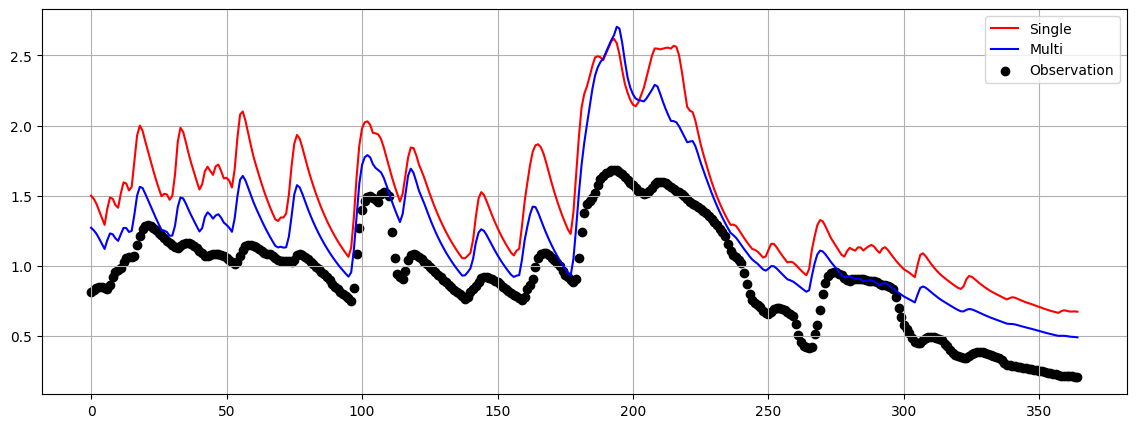

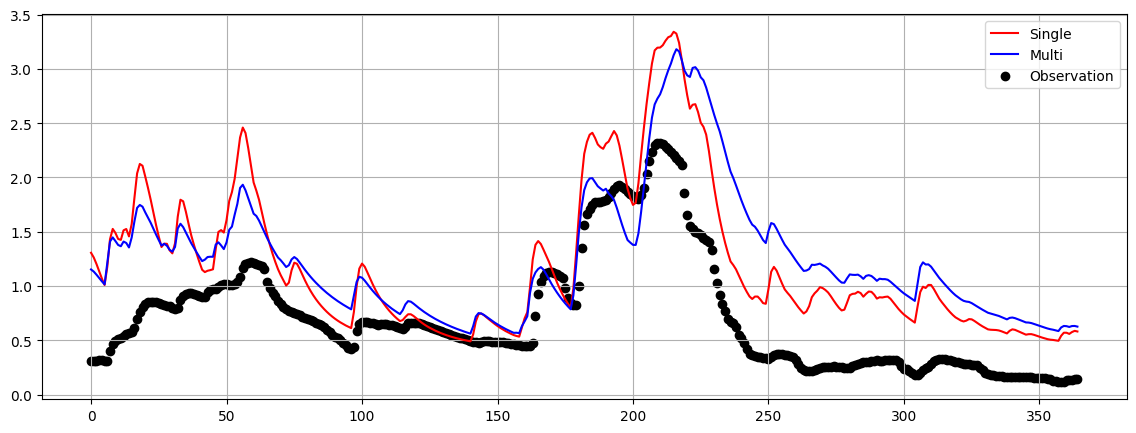

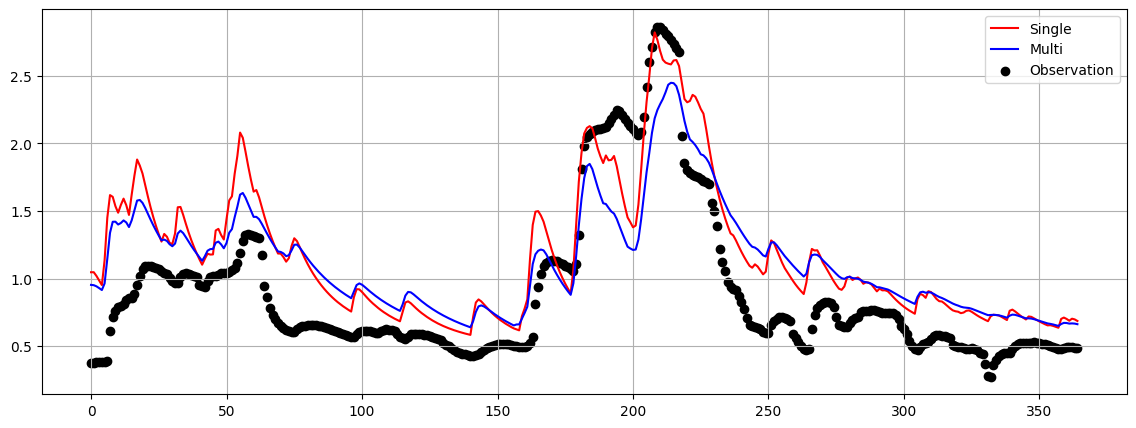

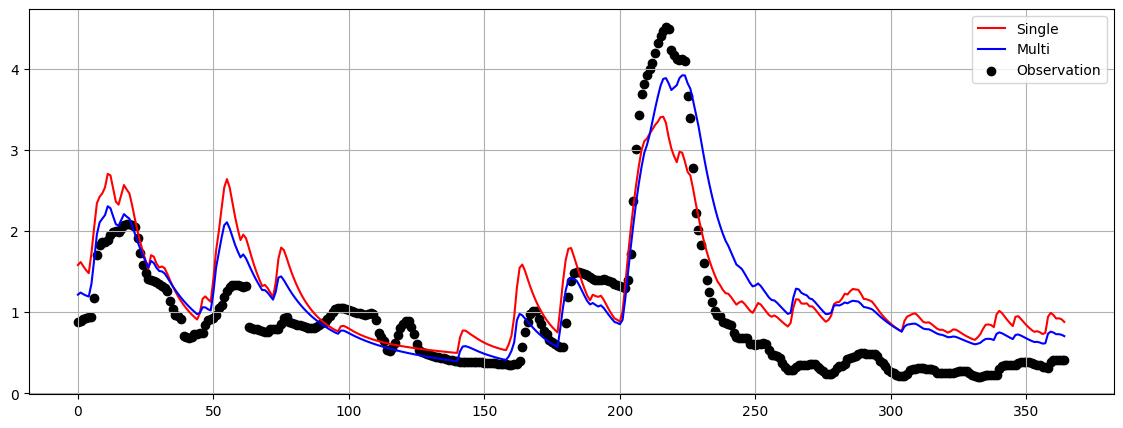

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

for k in range(1,2):
    obs= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_{k}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy")
    single= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single/Region_{k}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy")
    single= single.squeeze()
    multi= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_{k}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy")
    multi= multi.squeeze()
    
    nbasins = obs.shape[1]

    for b in range(4):

                plt.figure(figsize=(14,5))
                plt.plot(single[365:730,b],label= 'Single', color='red')
                plt.plot(multi[365:730,b],label= 'Multi', color='blue')
                plt.scatter(range(365),obs[365:730,b], label= 'Observation', color='black')
                plt.grid()
                plt.legend()
                plt.show()

In [3]:
import os
import numpy as np
print('Lag on Total Flow Simulation')
# ==========================================================
# SETTINGS
# ==========================================================
methods= ['Furey', 'USGS', 'Eckhardt', 'LocalHYSEP']



    # model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']


regions = [f"Region_{i}" for i in range(1, 8)]


# ==========================================================
# FUNCTIONS
# ==========================================================

def find_best_lag(x, y, max_lag=30):
    """
    Returns the lag that maximizes the Pearson correlation
    between x(t) and y(t + lag).
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if len(x) < max_lag + 10:
        return np.nan

    best_corr = -np.inf
    best_lag = np.nan

    for lag in range(max_lag + 1):

        if lag == 0:
            xx = x
            yy = y
        else:
            xx = x[:-lag]
            yy = y[lag:]

        if len(xx) < 10:
            continue

        xx = xx - xx.mean()
        yy = yy - yy.mean()

        sx = xx.std()
        sy = yy.std()

        if sx == 0 or sy == 0:
            continue

        corr = np.mean((xx / sx) * (yy / sy))

        if corr > best_corr:
            best_corr = corr
            best_lag = lag

    return best_lag


# ==========================================================
# MAIN LOOP
# ==========================================================

for method in methods:

    for model in models:
        BASE_DIR = "/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single"
        MULTI_DIR = f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi"

        methods = ["Furey", "USGS", "Eckhardt"]
        models = ["HBV", "marrmot_PRMS", "HBV_capillary"]

        dyn_map = {
            "HBV": "parBETA_parBETAET_",
            "marrmot_PRMS": "alpha_cgw_scx_tt_",
            "HBV_capillary": "parBETA_parBETAET_parK0_parUZL_",
        }

        dyn = dyn_map[model]

        model_dir = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999"
        )

        print(f"\nMethod : {method}")
        print(f"Model  : {model}")

        print("=" * 90)
        print(
            f"{'Region':<10}"
            f"{'Single Mean':>14}"
            f"{'Single Med':>14}"
            f"{'Multi Mean':>14}"
            f"{'Multi Med':>14}"
        )
        print("=" * 90)

        all_single = []
        all_multi = []

        for region in regions:

            single_folder = os.path.join(BASE_DIR, region, model_dir)
            multi_folder = os.path.join(MULTI_DIR, region, model_dir)


            obs_flow = np.load(
                os.path.join(multi_folder, "00060_Mean.npy")).squeeze()


            single_flow = np.load(
                os.path.join(single_folder, "flow_sim.npy")
            ).squeeze()

            multi_flow = np.load(
                os.path.join(multi_folder, "flow_sim.npy")
            ).squeeze()

            nbasins = obs_flow.shape[1]

            single_lags = np.full(nbasins, np.nan)
            multi_lags = np.full(nbasins, np.nan)

            for b in range(nbasins):

                single_lags[b] = find_best_lag(
                    obs_flow[:, b],
                    single_flow[:, b],
                    max_lag=30
                )

                multi_lags[b] = find_best_lag(
                    obs_flow[:, b],
                    multi_flow[:, b],
                    max_lag=30
                )

            all_single.extend(single_lags[np.isfinite(single_lags)])
            all_multi.extend(multi_lags[np.isfinite(multi_lags)])

            print(
                f"{region:<10}"
                f"{np.nanmean(single_lags):>14.2f}"
                f"{np.nanmedian(single_lags):>14.2f}"
                f"{np.nanmean(multi_lags):>14.2f}"
                f"{np.nanmedian(multi_lags):>14.2f}"
            )

        print("=" * 90)
        print(
            f"{'Overall':<10}"
            f"{np.nanmean(all_single):>14.2f}"
            f"{np.nanmedian(all_single):>14.2f}"
            f"{np.nanmean(all_multi):>14.2f}"
            f"{np.nanmedian(all_multi):>14.2f}"
        )
        print("=" * 90)

Lag on Total Flow Simulation

Method : Furey
Model  : HBV
Region       Single Mean    Single Med    Multi Mean     Multi Med
Region_1            0.01          0.00          0.07          0.00
Region_2            0.12          0.00          0.11          0.00
Region_3            0.03          0.00          0.03          0.00
Region_4            0.41          0.00          0.24          0.00
Region_5            0.15          0.00          0.35          0.00
Region_6            2.03          0.00          2.35          0.00
Region_7            0.04          0.00          0.18          0.00
Overall             0.32          0.00          0.39          0.00

Method : Furey
Model  : marrmot_PRMS
Region       Single Mean    Single Med    Multi Mean     Multi Med
Region_1            0.08          0.00          0.10          0.00
Region_2            0.15          0.00          0.21          0.00
Region_3            0.09          0.00          0.06          0.00
Region_4            0.39         

In [1]:
import os
import numpy as np
import pandas as pd
from dtaidistance import dtw

# Configuration Lists
methods = ["Furey", "USGS", "Eckhardt", 'LocalHYSEP']
models = ["HBV", "marrmot_PRMS", "HBV_capillary"]
regions = ["Region_1", "Region_2", "Region_3", "Region_4", "Region_5", "Region_6", "Region_7"]  # Replace with your actual region list

dyn_map = {
    "HBV": "parBETA_parBETAET_",
    "marrmot_PRMS": "alpha_cgw_scx_tt_",
    "HBV_capillary": "parBETA_parBETAET_parK0_parUZL_",
}

# Main Loop over methods and models
for method in methods:
    for model in models:
        BASE_DIR = "/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single"
        MULTI_DIR = f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi"

        dyn = dyn_map[model]

        model_dir = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999"
        )

        print(f"\nMethod : {method}")
        print(f"Model  : {model}")

        print("=" * 90)
        print(
            f"{'Region':<10}"
            f"{'Single Mean':>14}"
            f"{'Single Med':>14}"
            f"{'Multi Mean':>14}"
            f"{'Multi Med':>14}"
        )
        print("=" * 90)

        all_single_distances = []
        all_multi_distances = []

        for region in regions:
            single_folder = os.path.join(BASE_DIR, region, model_dir)
            multi_folder = os.path.join(MULTI_DIR, region, model_dir)

            try:
                obs_flow = np.load(
                    os.path.join(multi_folder, "00060_Mean.npy")
                ).squeeze()

                single_flow = np.load(
                    os.path.join(single_folder, "flow_sim.npy")
                ).squeeze()

                multi_flow = np.load(
                    os.path.join(multi_folder, "flow_sim.npy")
                ).squeeze()
            except FileNotFoundError as e:
                print(f"Skipping {region} due to missing file: {e}")
                continue

            nbasins = obs_flow.shape[1]

            single_dists = np.full(nbasins, np.nan)
            multi_dists = np.full(nbasins, np.nan)

            for b in range(nbasins):
                # 1. Single Flow Standard DTW Distance
                s1_single = np.ascontiguousarray(obs_flow[:, b], dtype=np.double)
                s2_single = np.ascontiguousarray(single_flow[:, b], dtype=np.double)
                
                valid_single = ~(np.isnan(s1_single) | np.isnan(s2_single))
                if np.sum(valid_single) > 10:
                    single_dists[b] = dtw.distance_fast(
                        s1_single[valid_single], 
                        s2_single[valid_single], 
                        use_pruning=True
                    )

                # 2. Multi Flow Standard DTW Distance
                s1_multi = np.ascontiguousarray(obs_flow[:, b], dtype=np.double)
                s2_multi = np.ascontiguousarray(multi_flow[:, b], dtype=np.double)
                
                valid_multi = ~(np.isnan(s1_multi) | np.isnan(s2_multi))
                if np.sum(valid_multi) > 10:
                    multi_dists[b] = dtw.distance_fast(
                        s1_multi[valid_multi], 
                        s2_multi[valid_multi], 
                        use_pruning=True
                    )

            # Convert basin distance array into Pandas Series for this region
            single_series = pd.Series(single_dists)
            multi_series = pd.Series(multi_dists)

            all_single_distances.extend(single_dists[~np.isnan(single_dists)])
            all_multi_distances.extend(multi_dists[~np.isnan(multi_dists)])

            print(
                f"{region:<10}"
                f"{single_series.mean():>14.2f}"
                f"{single_series.median():>14.2f}"
                f"{multi_series.mean():>14.2f}"
                f"{multi_series.median():>14.2f}"
            )

        # Overall summary as Pandas Series across all regions
        overall_single_series = pd.Series(all_single_distances)
        overall_multi_series = pd.Series(all_multi_distances)

        print("=" * 90)
        print(
            f"{'Overall':<10}"
            f"{overall_single_series.mean():>14.2f}"
            f"{overall_single_series.median():>14.2f}"
            f"{overall_multi_series.mean():>14.2f}"
            f"{overall_multi_series.median():>14.2f}"
        )
        print("=" * 90)


Method : Furey
Model  : HBV
Region       Single Mean    Single Med    Multi Mean     Multi Med


Region_1           71.26         63.68         71.58         63.92
Region_2           76.03         63.63         75.41         64.21
Region_3           59.71         57.43         59.68         59.48
Region_4           48.19         40.81         46.85         43.01
Region_5           70.05         56.09         72.61         60.47
Region_6           70.39         53.80         69.51         56.42
Region_7          136.00        119.61        137.14        121.59
Overall            76.40         62.92         76.59         63.75

Method : Furey
Model  : marrmot_PRMS
Region       Single Mean    Single Med    Multi Mean     Multi Med
Region_1           71.31         65.68         72.08         64.49
Region_2           76.64         72.60         76.58         69.23
Region_3           60.83         60.10         61.17         60.69
Region_4           47.01         42.16         44.87         41.57
Region_5           73.18         59.61         72.28         56.69
Region_6           72.17

In [2]:
import os
import numpy as np
import pandas as pd
from dtaidistance import dtw

print('Lag for Baseflow')
# Configuration Lists
methods = ["Furey", "USGS", "Eckhardt", "LocalHYSEP"]
models = ["HBV", "marrmot_PRMS", "HBV_capillary"]
regions = ["Region_1", "Region_2", "Region_3", "Region_4", "Region_5", "Region_6", "Region_7"]  # Replace with your actual region list

dyn_map = {
    "HBV": "parBETA_parBETAET_",
    "marrmot_PRMS": "alpha_cgw_scx_tt_",
    "HBV_capillary": "parBETA_parBETAET_parK0_parUZL_",
}

# Main Loop over methods and models
for method in methods:
    for model in models:
        BASE_DIR = "/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single"
        MULTI_DIR = f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi"

        dyn = dyn_map[model]

        model_dir = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999"
        )

        print(f"\nMethod : {method}")
        print(f"Model  : {model}")

        print("=" * 90)
        print(
            f"{'Region':<10}"
            f"{'Single Mean':>14}"
            f"{'Single Med':>14}"
            f"{'Multi Mean':>14}"
            f"{'Multi Med':>14}"
        )
        print("=" * 90)

        all_single_distances = []
        all_multi_distances = []

        for region in regions:
            single_folder = os.path.join(BASE_DIR, region, model_dir)
            multi_folder = os.path.join(MULTI_DIR, region, model_dir)

            try:
                obs_flow = np.load(
                    os.path.join(multi_folder, "baseflow.npy")
                ).squeeze()

                single_flow = np.load(
                    os.path.join(single_folder, "gwflow.npy")
                ).squeeze()

                multi_flow = np.load(
                    os.path.join(multi_folder, "gwflow.npy")
                ).squeeze()
            except FileNotFoundError as e:
                print(f"Skipping {region} due to missing file: {e}")
                continue

            nbasins = obs_flow.shape[1]

            single_dists = np.full(nbasins, np.nan)
            multi_dists = np.full(nbasins, np.nan)

            for b in range(nbasins):
                # 1. Single Flow Standard DTW Distance
                s1_single = np.ascontiguousarray(obs_flow[:, b], dtype=np.double)
                s2_single = np.ascontiguousarray(single_flow[:, b], dtype=np.double)
                
                valid_single = ~(np.isnan(s1_single) | np.isnan(s2_single))
                if np.sum(valid_single) > 10:
                    single_dists[b] = dtw.distance_fast(
                        s1_single[valid_single], 
                        s2_single[valid_single], 
                        use_pruning=True
                    )

                # 2. Multi Flow Standard DTW Distance
                s1_multi = np.ascontiguousarray(obs_flow[:, b], dtype=np.double)
                s2_multi = np.ascontiguousarray(multi_flow[:, b], dtype=np.double)
                
                valid_multi = ~(np.isnan(s1_multi) | np.isnan(s2_multi))
                if np.sum(valid_multi) > 10:
                    multi_dists[b] = dtw.distance_fast(
                        s1_multi[valid_multi], 
                        s2_multi[valid_multi], 
                        use_pruning=True
                    )

            # Convert basin distance array into Pandas Series for this region
            single_series = pd.Series(single_dists)
            multi_series = pd.Series(multi_dists)

            all_single_distances.extend(single_dists[~np.isnan(single_dists)])
            all_multi_distances.extend(multi_dists[~np.isnan(multi_dists)])

            print(
                f"{region:<10}"
                f"{single_series.mean():>14.2f}"
                f"{single_series.median():>14.2f}"
                f"{multi_series.mean():>14.2f}"
                f"{multi_series.median():>14.2f}"
            )

        # Overall summary as Pandas Series across all regions
        overall_single_series = pd.Series(all_single_distances)
        overall_multi_series = pd.Series(all_multi_distances)

        print("=" * 90)
        print(
            f"{'Overall':<10}"
            f"{overall_single_series.mean():>14.2f}"
            f"{overall_single_series.median():>14.2f}"
            f"{overall_multi_series.mean():>14.2f}"
            f"{overall_multi_series.median():>14.2f}"
        )
        print("=" * 90)

Lag for Baseflow

Method : Furey
Model  : HBV
Region       Single Mean    Single Med    Multi Mean     Multi Med
Region_1           19.79         16.92         13.04         12.03
Region_2           14.87         13.98         12.13         10.58
Region_3           11.61         11.85          7.91          7.32
Region_4           13.64         10.12         11.17          5.99
Region_5           11.44         10.77          9.96          8.26
Region_6           27.98         19.60         23.60         20.21
Region_7           54.61         43.85         45.64         40.58
Overall            21.46         14.40         17.02         10.76

Method : Furey
Model  : marrmot_PRMS
Region       Single Mean    Single Med    Multi Mean     Multi Med
Region_1           20.60         19.34         13.19         12.37
Region_2           15.27         13.15         12.15         10.29
Region_3           17.63         16.17          8.14          7.71
Region_4           12.25          8.66       

In [1]:
import os
import numpy as np
import pandas as pd
from dtaidistance import dtw

test= 'PUB' #PUR/PUB
print(f'Lag for Baseflow using {test}')
# Configuration Lists
methods = ["Furey", "USGS", "Eckhardt", 'LocalHYSEP']
models = ["HBV", "marrmot_PRMS", "HBV_capillary"]
if test=='PUR':
    regions = ["Region_1", "Region_2", "Region_3", "Region_4", "Region_5", "Region_6", "Region_7"]  # Replace with your actual region list

if test=='PUB':
    regions=['1','2','3','4','5','6','7','8','9','10']

dyn_map = {
    "HBV": "parBETA_parBETAET_",
    "marrmot_PRMS": "alpha_cgw_scx_tt_",
    "HBV_capillary": "parBETA_parBETAET_parK0_parUZL_",
}

# Main Loop over methods and models
for method in methods:
    for model in models:
        BASE_DIR = f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_{test}_Single"
        MULTI_DIR = f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/{method}_Multi"

        dyn = dyn_map[model]

        model_dir = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999"
        )

        print(f"\nMethod : {method}")
        print(f"Model  : {model}")

        print("=" * 90)
        print(
            f"{'Region':<10}"
            f"{'Single Mean':>14}"
            f"{'Single Med':>14}"
            f"{'Multi Mean':>14}"
            f"{'Multi Med':>14}"
        )
        print("=" * 90)

        all_single_distances = []
        all_multi_distances = []

        for region in regions:
            single_folder = os.path.join(BASE_DIR, region, model_dir)
            multi_folder = os.path.join(MULTI_DIR, region, model_dir)

            try:
                obs_flow = np.load(
                    os.path.join(multi_folder, "baseflow.npy")
                ).squeeze()

                single_flow = np.load(
                    os.path.join(single_folder, "gwflow.npy")
                ).squeeze()

                multi_flow = np.load(
                    os.path.join(multi_folder, "gwflow.npy")
                ).squeeze()
            except FileNotFoundError as e:
                print(f"Skipping {region} due to missing file: {e}")
                continue

            nbasins = obs_flow.shape[1]

            single_dists = np.full(nbasins, np.nan)
            multi_dists = np.full(nbasins, np.nan)

            for b in range(nbasins):
                # 1. Single Flow Standard DTW Distance
                s1_single = np.ascontiguousarray(obs_flow[:, b], dtype=np.double)
                s2_single = np.ascontiguousarray(single_flow[:, b], dtype=np.double)
                
                valid_single = ~(np.isnan(s1_single) | np.isnan(s2_single))
                if np.sum(valid_single) > 10:
                    single_dists[b] = dtw.distance_fast(
                        s1_single[valid_single], 
                        s2_single[valid_single], 
                        use_pruning=True
                    )

                # 2. Multi Flow Standard DTW Distance
                s1_multi = np.ascontiguousarray(obs_flow[:, b], dtype=np.double)
                s2_multi = np.ascontiguousarray(multi_flow[:, b], dtype=np.double)
                
                valid_multi = ~(np.isnan(s1_multi) | np.isnan(s2_multi))
                if np.sum(valid_multi) > 10:
                    multi_dists[b] = dtw.distance_fast(
                        s1_multi[valid_multi], 
                        s2_multi[valid_multi], 
                        use_pruning=True
                    )

            # Convert basin distance array into Pandas Series for this region
            single_series = pd.Series(single_dists)
            multi_series = pd.Series(multi_dists)

            all_single_distances.extend(single_dists[~np.isnan(single_dists)])
            all_multi_distances.extend(multi_dists[~np.isnan(multi_dists)])

            print(
                f"{region:<10}"
                f"{single_series.mean():>14.2f}"
                f"{single_series.median():>14.2f}"
                f"{multi_series.mean():>14.2f}"
                f"{multi_series.median():>14.2f}"
            )

        # Overall summary as Pandas Series across all regions
        overall_single_series = pd.Series(all_single_distances)
        overall_multi_series = pd.Series(all_multi_distances)

        print("=" * 90)
        print(
            f"{'Overall':<10}"
            f"{overall_single_series.mean():>14.2f}"
            f"{overall_single_series.median():>14.2f}"
            f"{overall_multi_series.mean():>14.2f}"
            f"{overall_multi_series.median():>14.2f}"
        )
        print("=" * 90)

Lag for Baseflow using PUB

Method : Furey
Model  : HBV
Region       Single Mean    Single Med    Multi Mean     Multi Med
1                  18.79         13.35         14.05         10.64
2                  20.35         14.15         15.70         10.09
3                  20.06         15.85         16.84         11.28
4                  18.16         12.79         12.10          7.98
5                  18.84         13.03         14.03          9.41
6                  18.16         13.32         14.34          8.68
7                  18.44         13.44         13.77          9.88
8                  22.78         13.67         15.65         10.33
9                  17.16         11.94         15.26          9.68
10                 20.74         13.86         16.36          9.77
Overall            19.38         13.66         14.83          9.64

Method : Furey
Model  : marrmot_PRMS
Region       Single Mean    Single Med    Multi Mean     Multi Med
1                  19.18         13

Saved plot: dtw_box_HBV_Furey.png


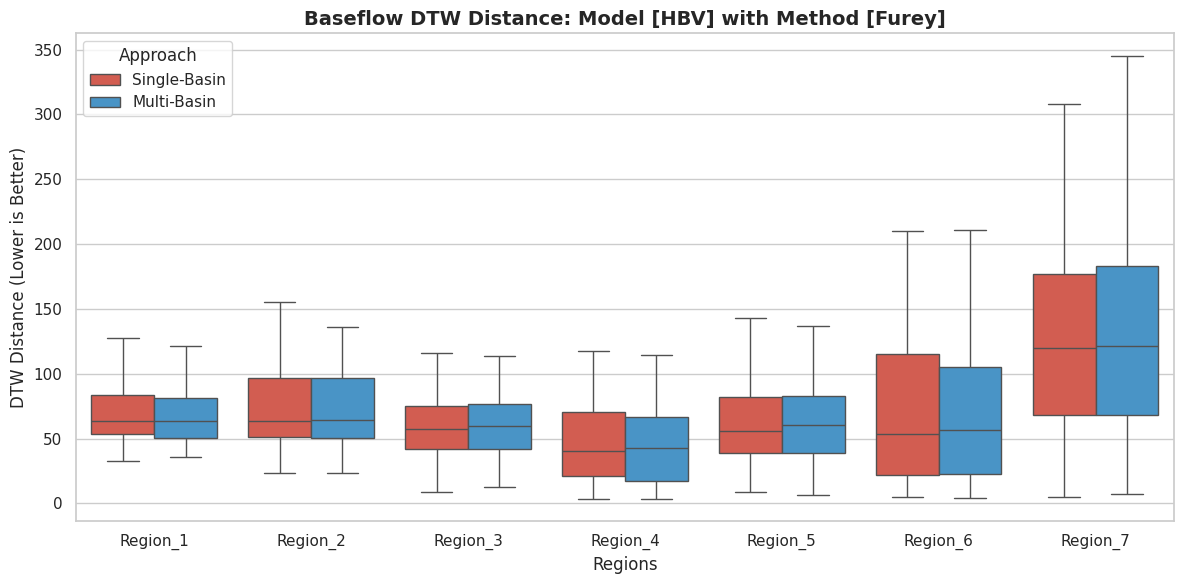

Saved plot: dtw_box_marrmot_PRMS_Furey.png


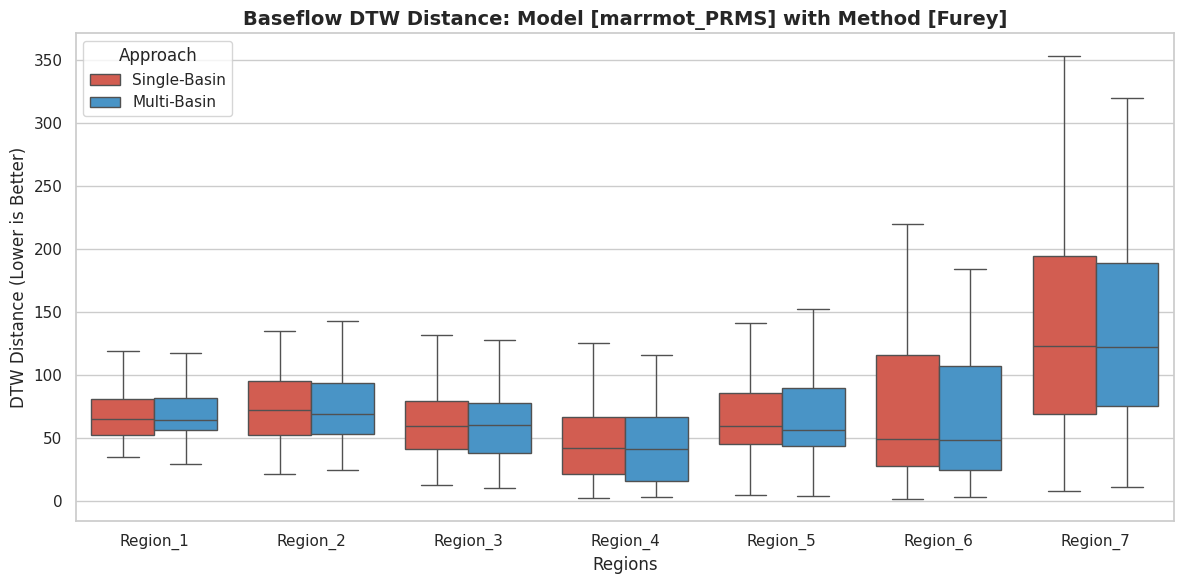

Saved plot: dtw_box_HBV_capillary_Furey.png


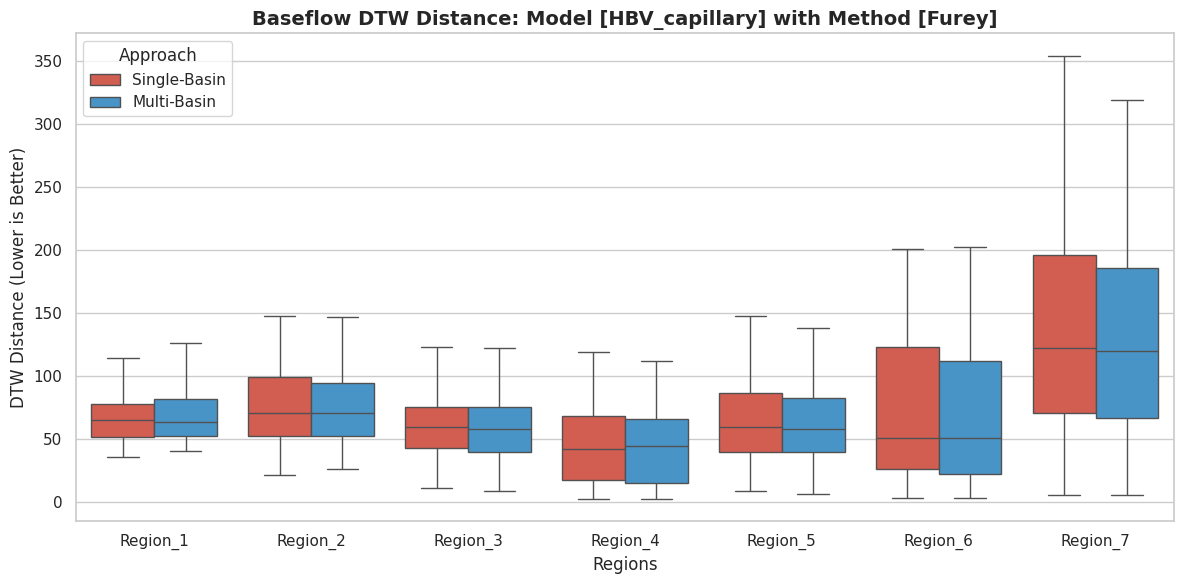

Saved plot: dtw_box_HBV_USGS.png


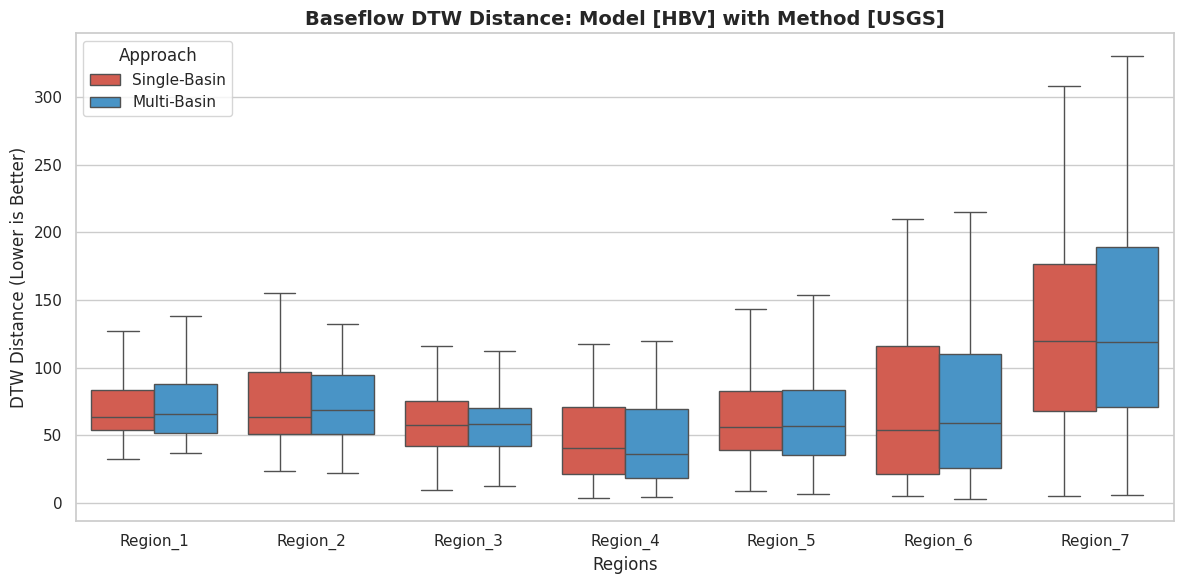

Saved plot: dtw_box_marrmot_PRMS_USGS.png


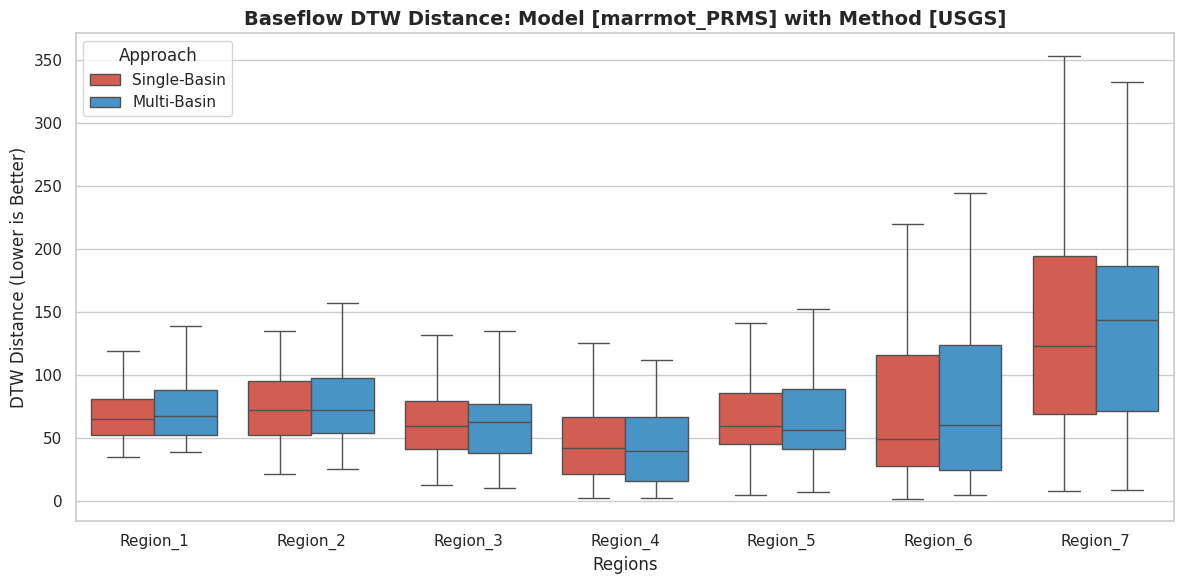

Saved plot: dtw_box_HBV_capillary_USGS.png


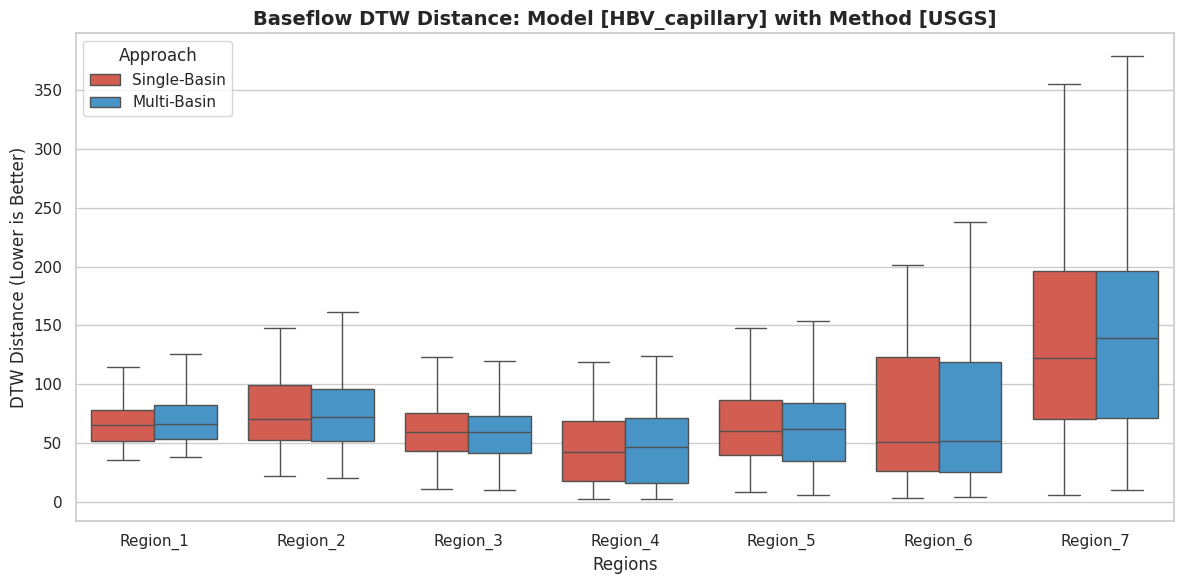

Saved plot: dtw_box_HBV_Eckhardt.png


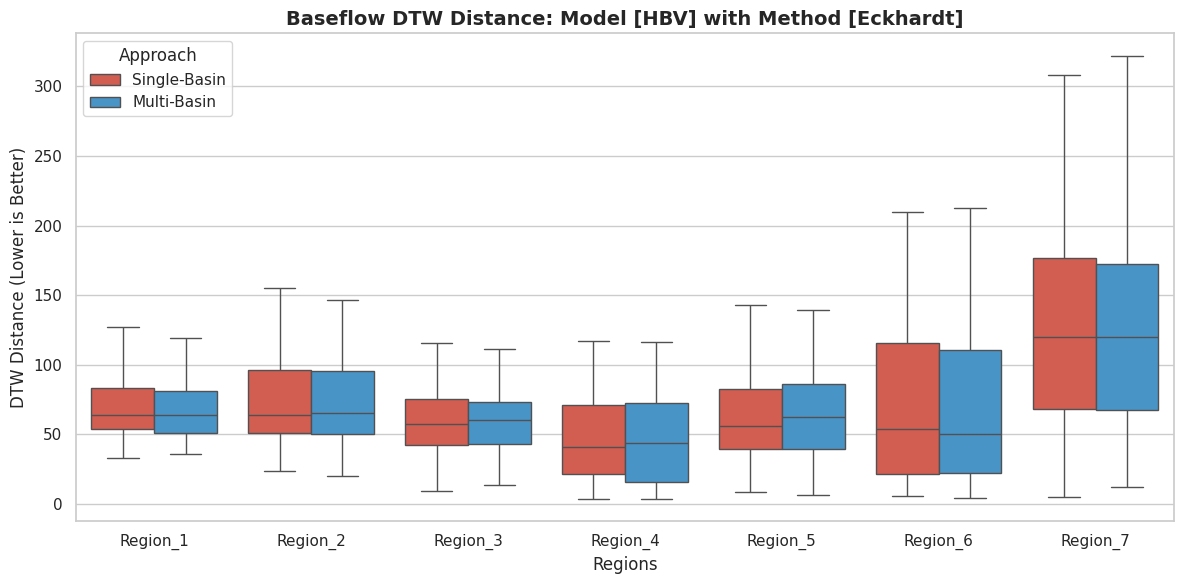

Saved plot: dtw_box_marrmot_PRMS_Eckhardt.png


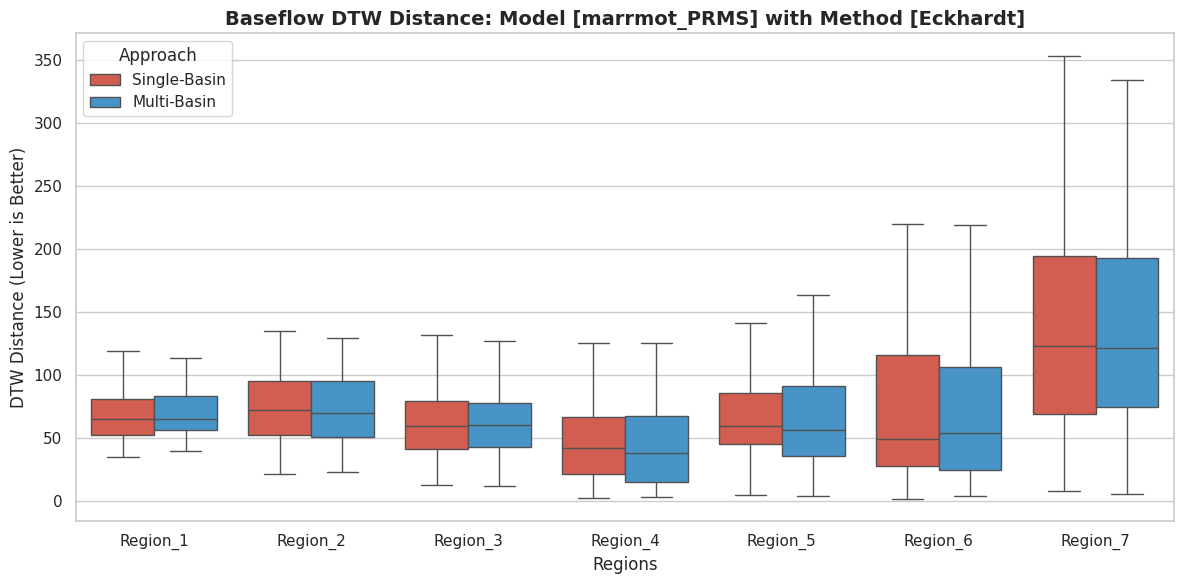

Saved plot: dtw_box_HBV_capillary_Eckhardt.png


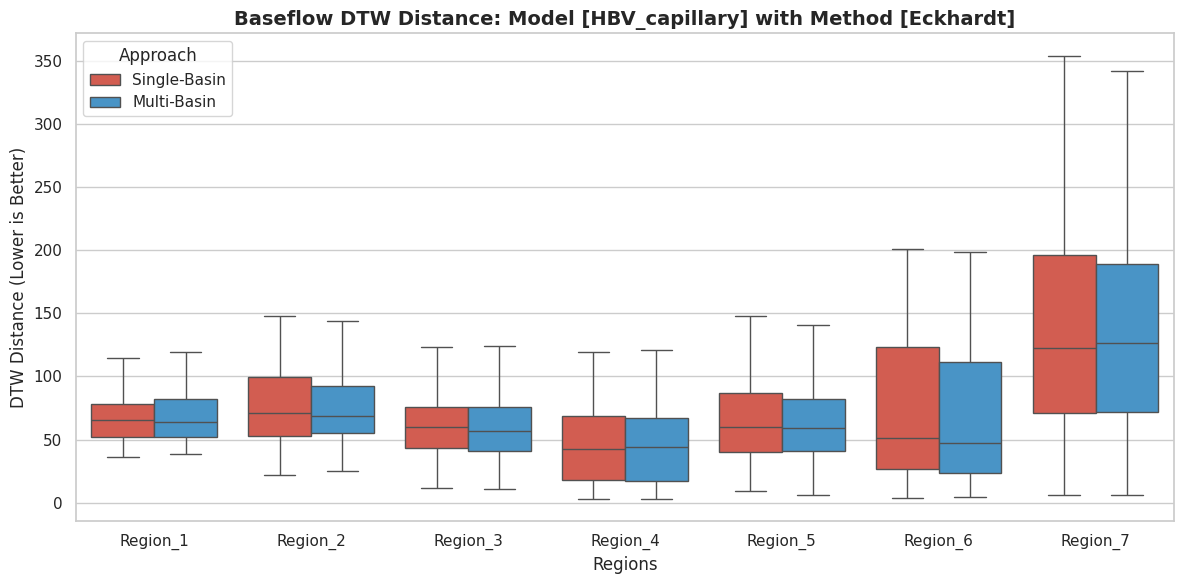

Saved plot: dtw_box_HBV_LocalHYSEP.png


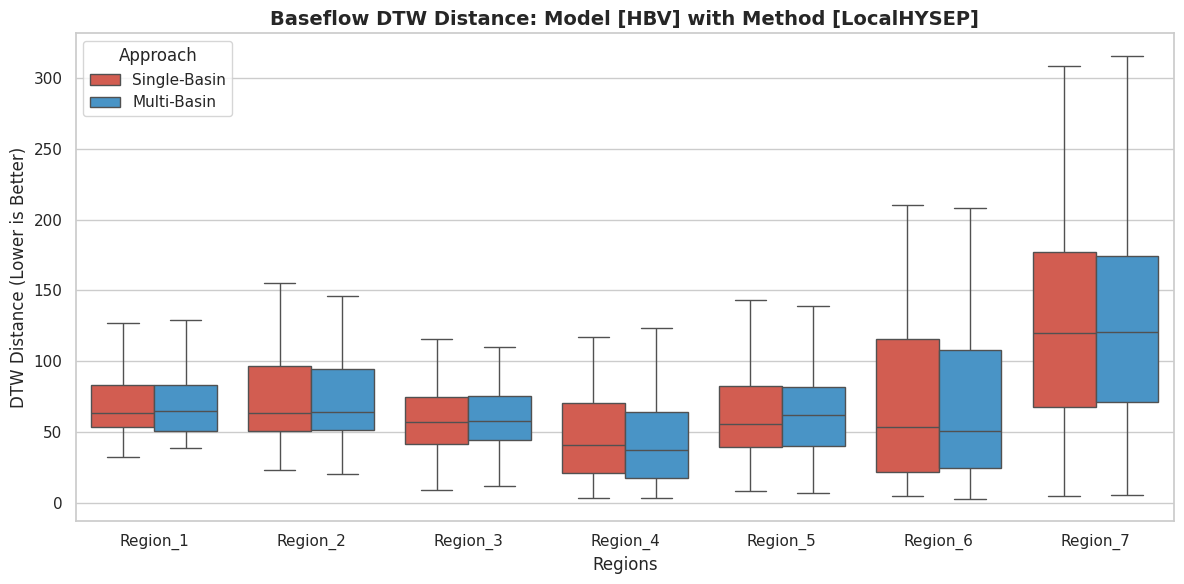

Saved plot: dtw_box_marrmot_PRMS_LocalHYSEP.png


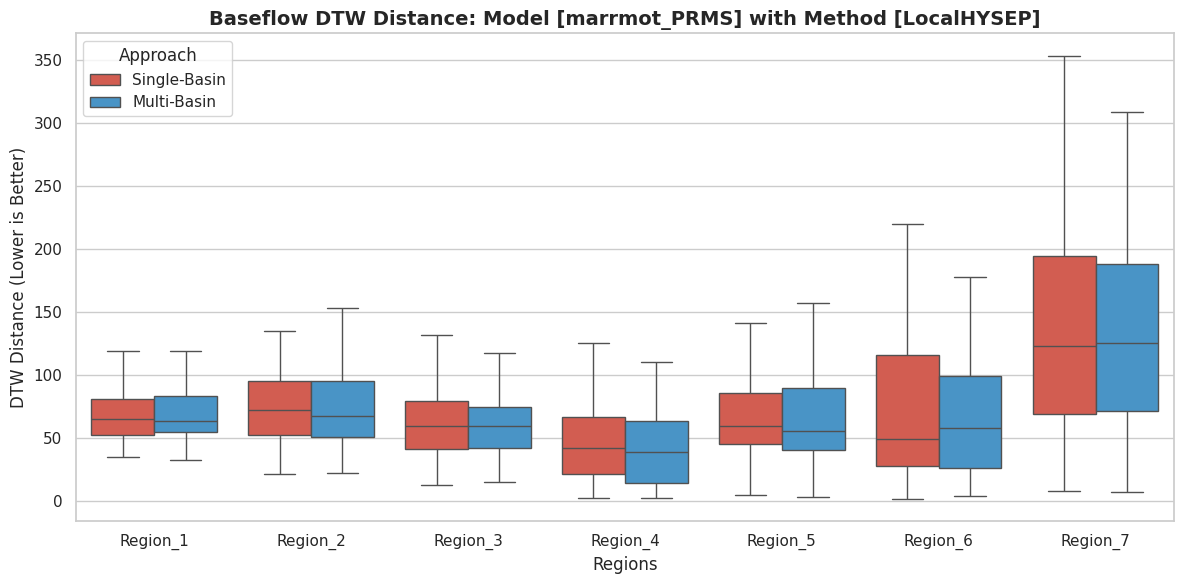

Saved plot: dtw_box_HBV_capillary_LocalHYSEP.png


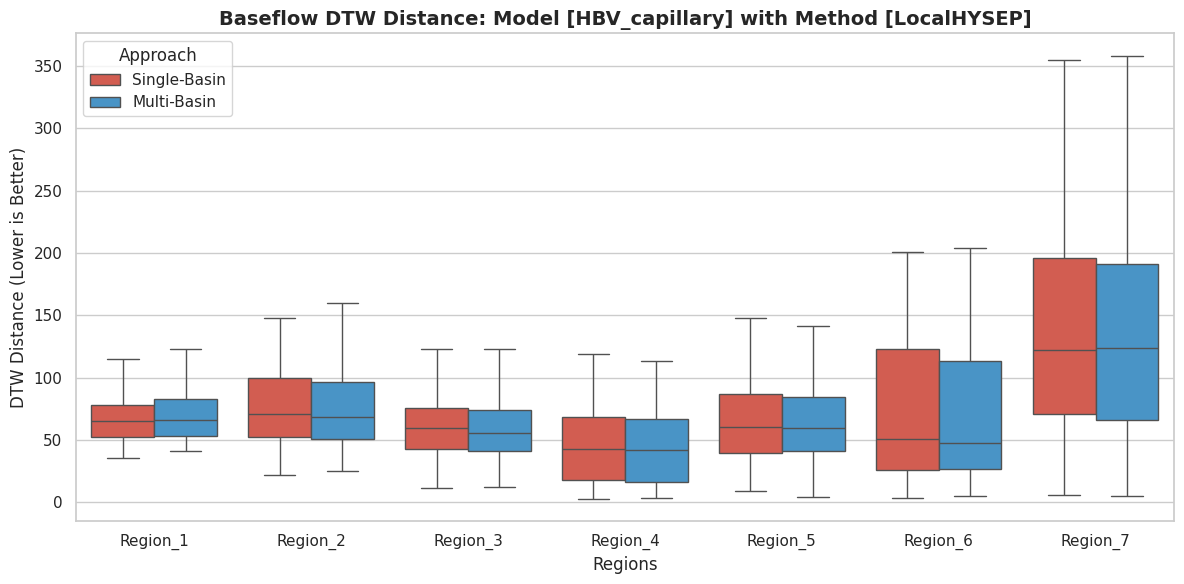

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dtaidistance import dtw

# --- Configuration Lists ---
methods = ["Furey", "USGS", "Eckhardt", "LocalHYSEP"]
models = ["HBV", "marrmot_PRMS", "HBV_capillary"]
regions = ["Region_1", "Region_2", "Region_3", "Region_4", "Region_5", "Region_6", "Region_7"]

BASE_DIR = "/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single"
dyn_map = {
    "HBV": "parBETA_parBETAET_",
    "marrmot_PRMS": "alpha_cgw_scx_tt_",
    "HBV_capillary": "parBETA_parBETAET_parK0_parUZL_",
}

# --- Nested Loop for Methods and Models ---
for method in methods:
    for model in models:
        MULTI_DIR = f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi"
        dyn = dyn_map[model]
        
        model_dir = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999"
        )

        plot_data = []

        for region in regions:
            single_folder = os.path.join(BASE_DIR, region, model_dir)
            multi_folder = os.path.join(MULTI_DIR, region, model_dir)

            try:
                obs_flow = np.load(os.path.join(multi_folder, "00060_Mean.npy")).squeeze()
                single_flow = np.load(os.path.join(single_folder, "flow_sim.npy")).squeeze()
                multi_flow = np.load(os.path.join(multi_folder, "flow_sim.npy")).squeeze()
            except FileNotFoundError:
                continue

            nbasins = obs_flow.shape[1]
            for b in range(nbasins):
                s1 = np.ascontiguousarray(obs_flow[:, b], dtype=np.double)
                s2_s = np.ascontiguousarray(single_flow[:, b], dtype=np.double)
                s2_m = np.ascontiguousarray(multi_flow[:, b], dtype=np.double)

                # Single distance calculation
                valid_s = ~(np.isnan(s1) | np.isnan(s2_s))
                if np.sum(valid_s) > 10:
                    d_single = dtw.distance_fast(s1[valid_s], s2_s[valid_s], use_pruning=True)
                    plot_data.append({"Region": region, "Model Type": "Single-Basin", "DTW Distance": d_single})

                # Multi distance calculation
                valid_m = ~(np.isnan(s1) | np.isnan(s2_m))
                if np.sum(valid_m) > 10:
                    d_multi = dtw.distance_fast(s1[valid_m], s2_m[valid_m], use_pruning=True)
                    plot_data.append({"Region": region, "Model Type": "Multi-Basin", "DTW Distance": d_multi})

        if not plot_data:
            print(f"Skipping plot for {method} - {model}: No data found.")
            continue

        df_plot = pd.DataFrame(plot_data)

        # --- Plotting Boxplot ---
        plt.figure(figsize=(12, 6))
        sns.set_theme(style="whitegrid")

        sns.boxplot(
            data=df_plot, 
            x="Region", 
            y="DTW Distance", 
            hue="Model Type", 
            palette={"Single-Basin": "#e74c3c", "Multi-Basin": "#3498db"},
            showfliers=False # Keeps the plot clean of extreme error outliers
        )

        plt.title(f"Baseflow DTW Distance: Model [{model}] with Method [{method}]", fontsize=14, fontweight='bold')
        plt.xlabel("Regions", fontsize=12)
        plt.ylabel("DTW Distance (Lower is Better)", fontsize=12)
        plt.legend(title="Approach")
        plt.tight_layout()

        # Save individual figures automatically for your paper
        plot_filename = f"dtw_box_{model}_{method}.png"
        # plt.savefig(plot_filename, dpi=300)
        print(f"Saved plot: {plot_filename}")
        
        plt.show() # Close figure to free up memory across the large loop

Saved plot: dtw_box_HBV_Furey.png


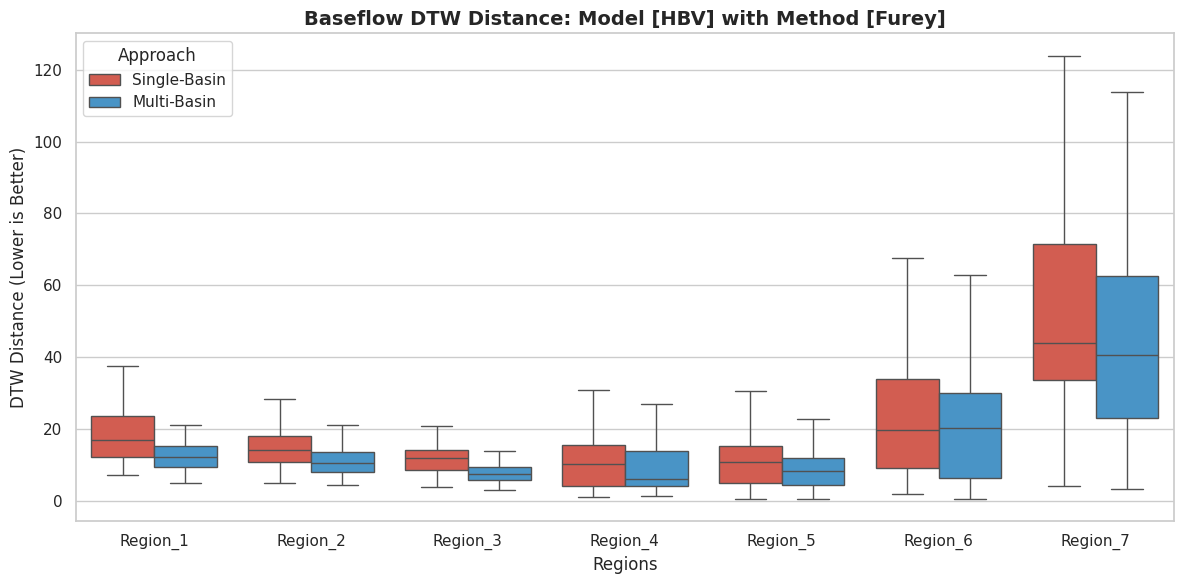

Saved plot: dtw_box_marrmot_PRMS_Furey.png


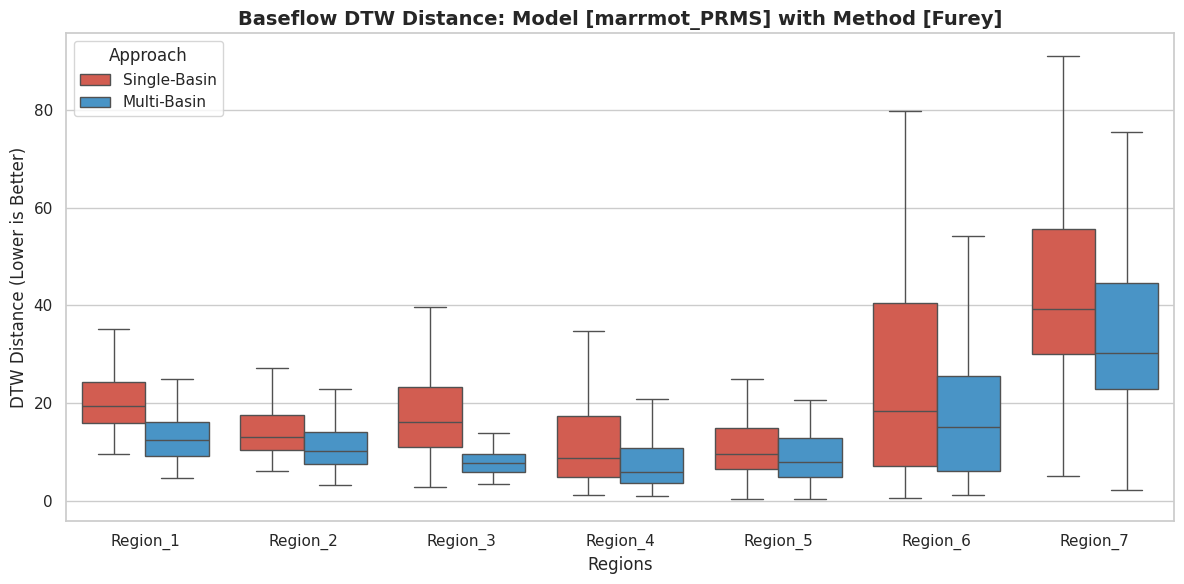

Saved plot: dtw_box_HBV_capillary_Furey.png


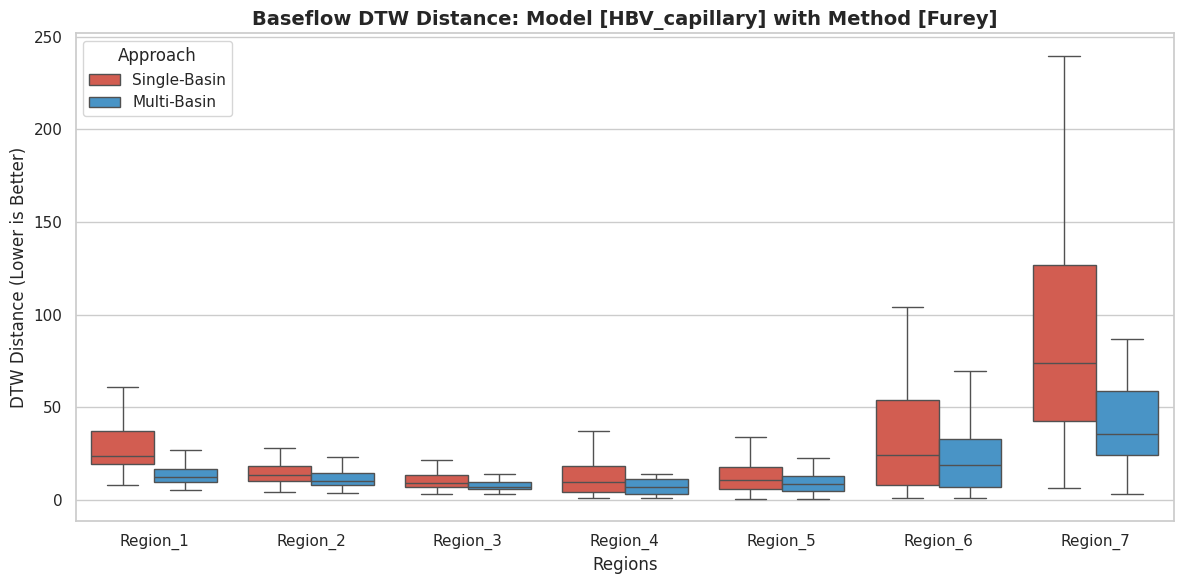

Saved plot: dtw_box_HBV_USGS.png


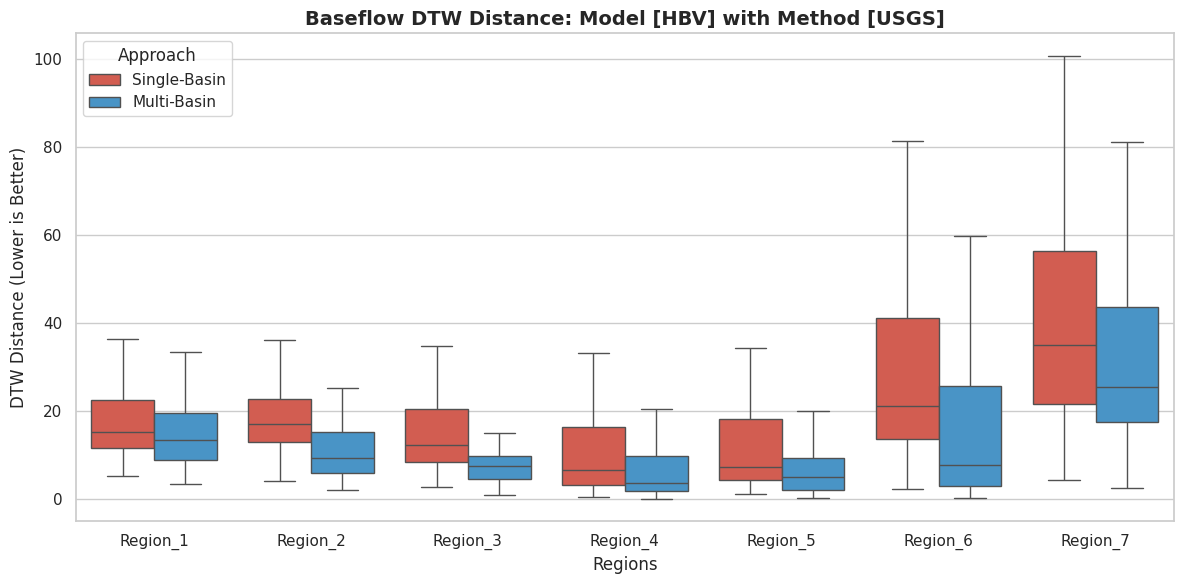

Saved plot: dtw_box_marrmot_PRMS_USGS.png


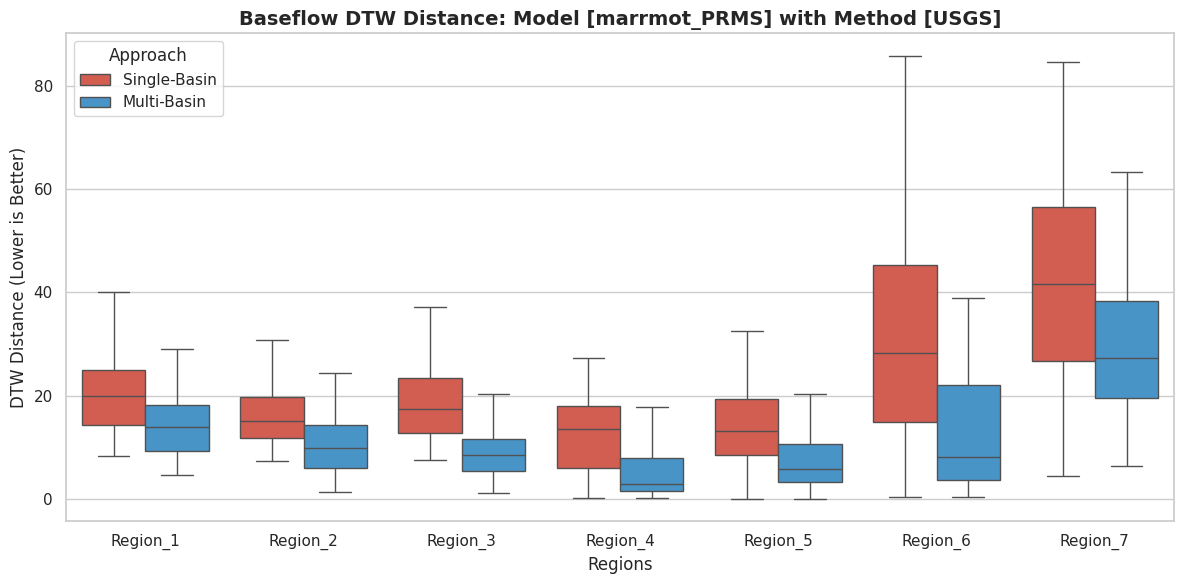

Saved plot: dtw_box_HBV_capillary_USGS.png


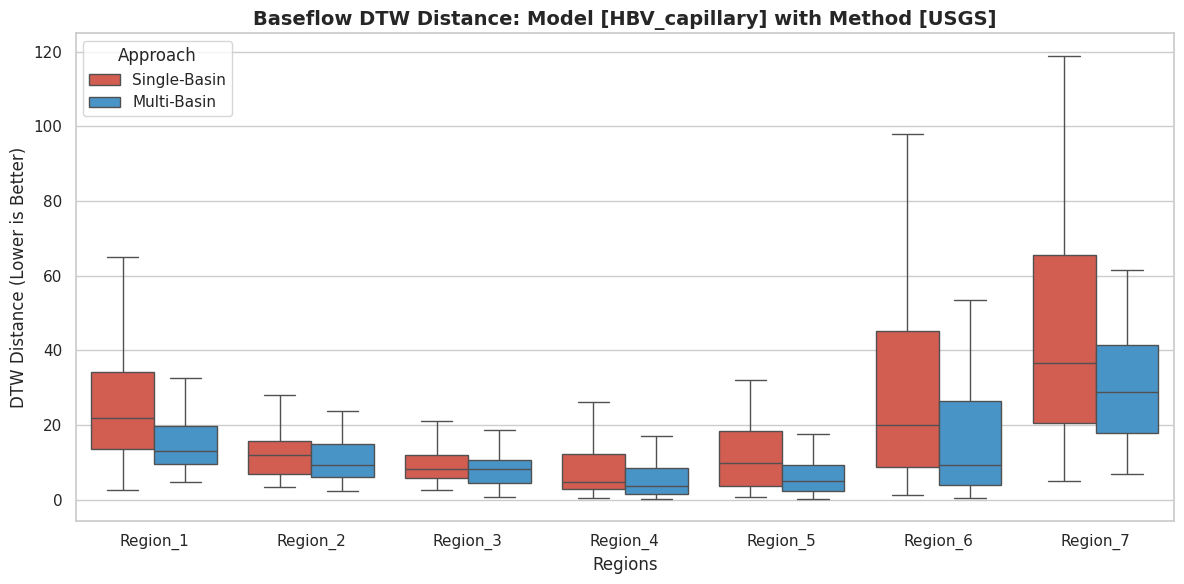

Saved plot: dtw_box_HBV_Eckhardt.png


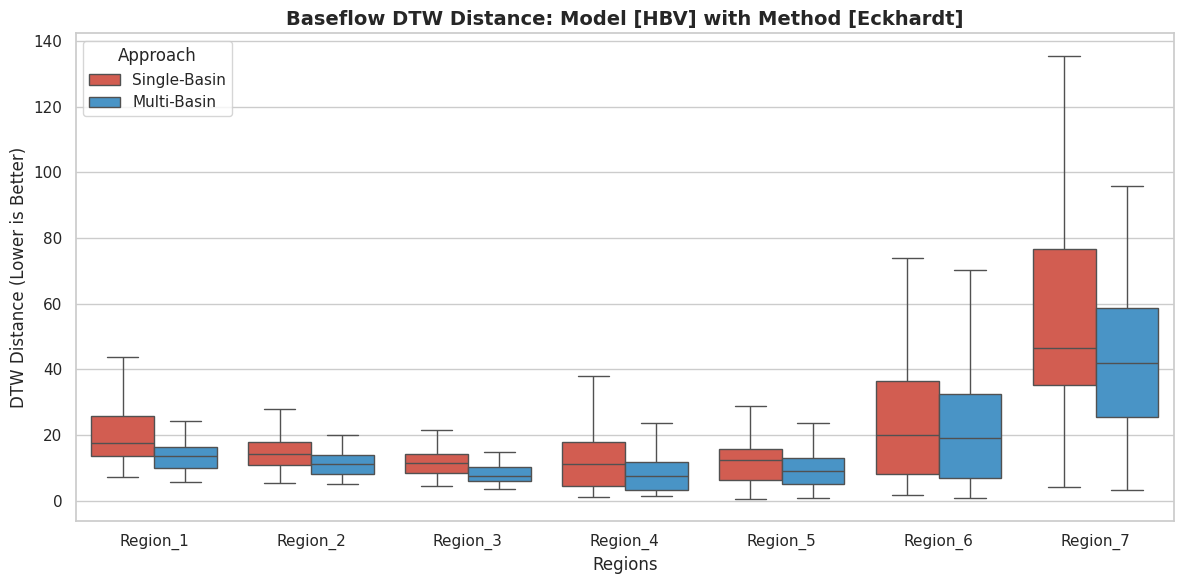

Saved plot: dtw_box_marrmot_PRMS_Eckhardt.png


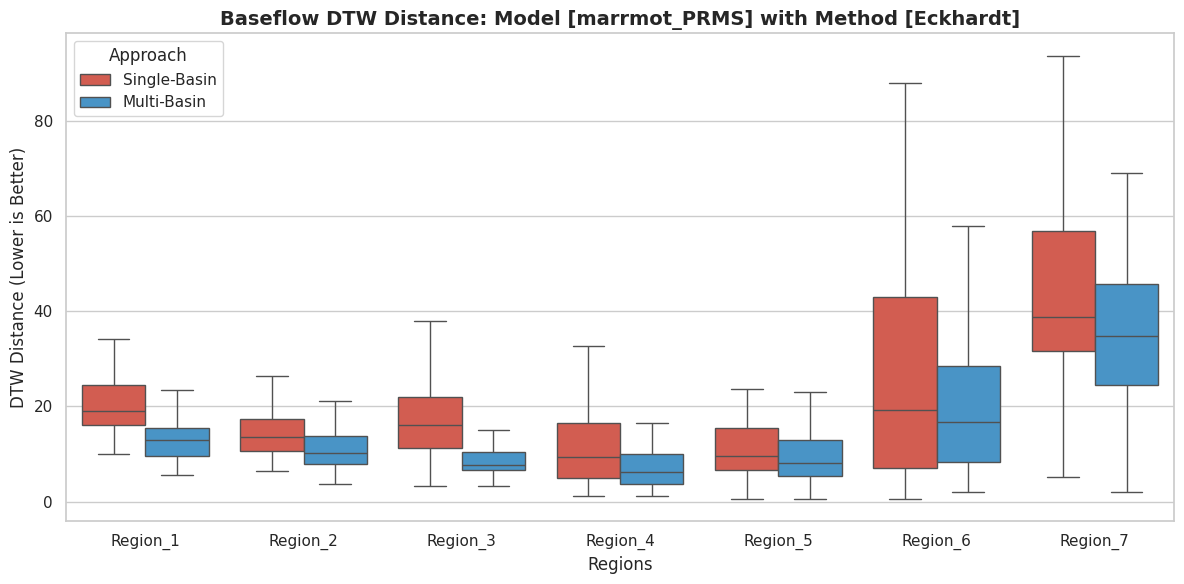

Saved plot: dtw_box_HBV_capillary_Eckhardt.png


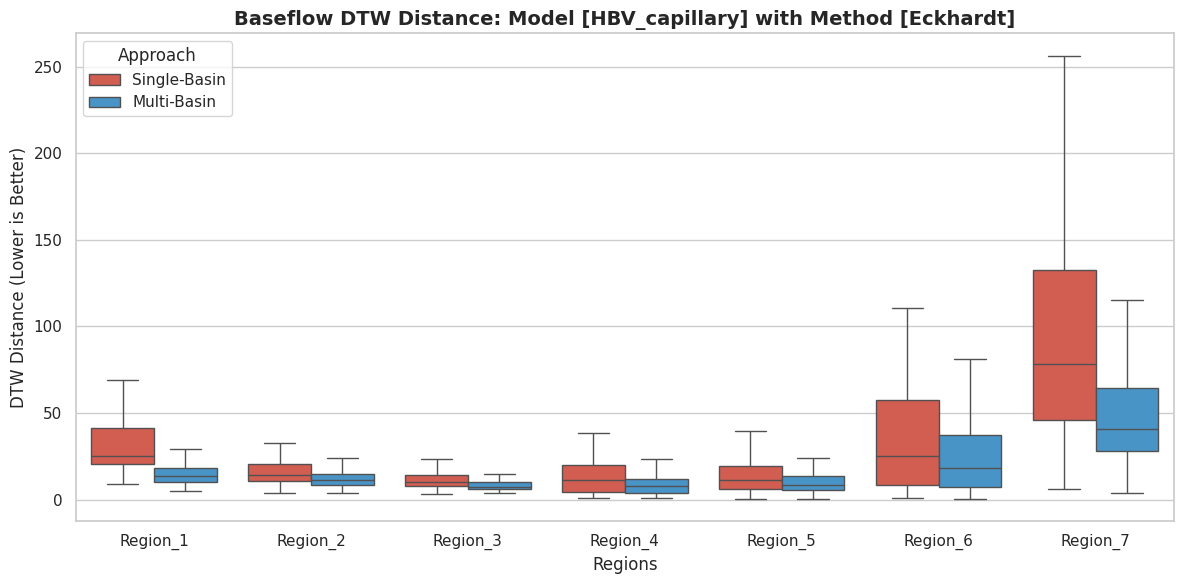

Saved plot: dtw_box_HBV_LocalHYSEP.png


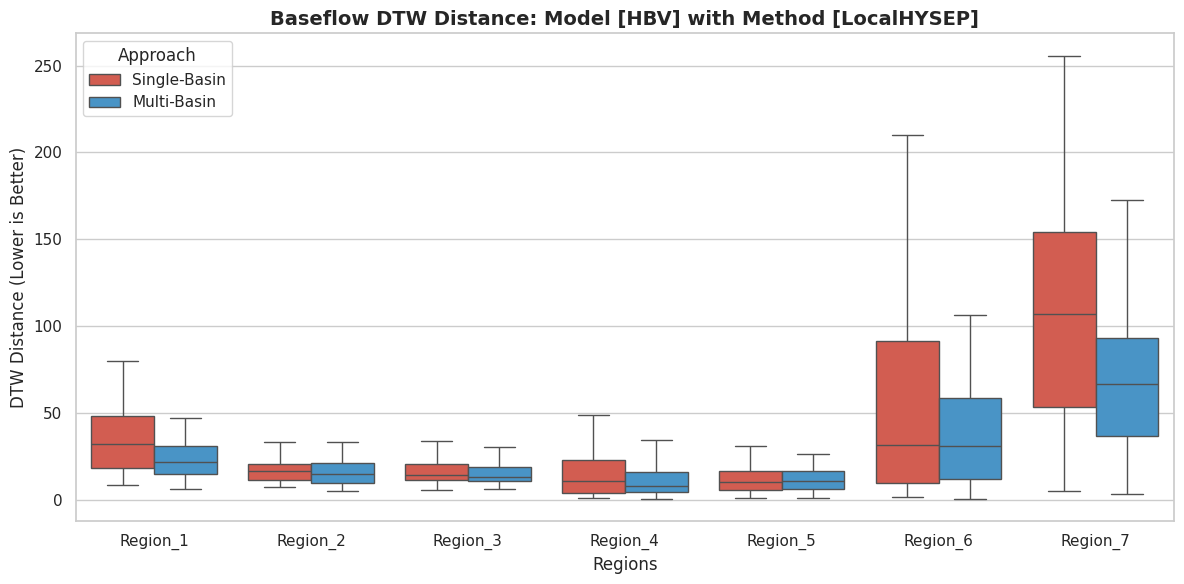

Saved plot: dtw_box_marrmot_PRMS_LocalHYSEP.png


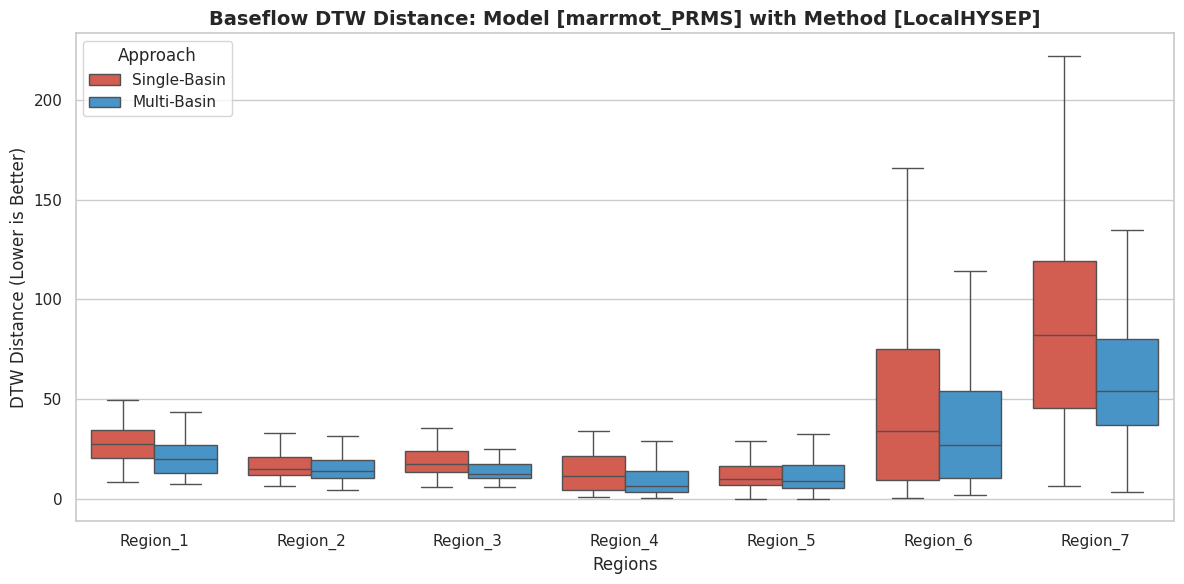

Saved plot: dtw_box_HBV_capillary_LocalHYSEP.png


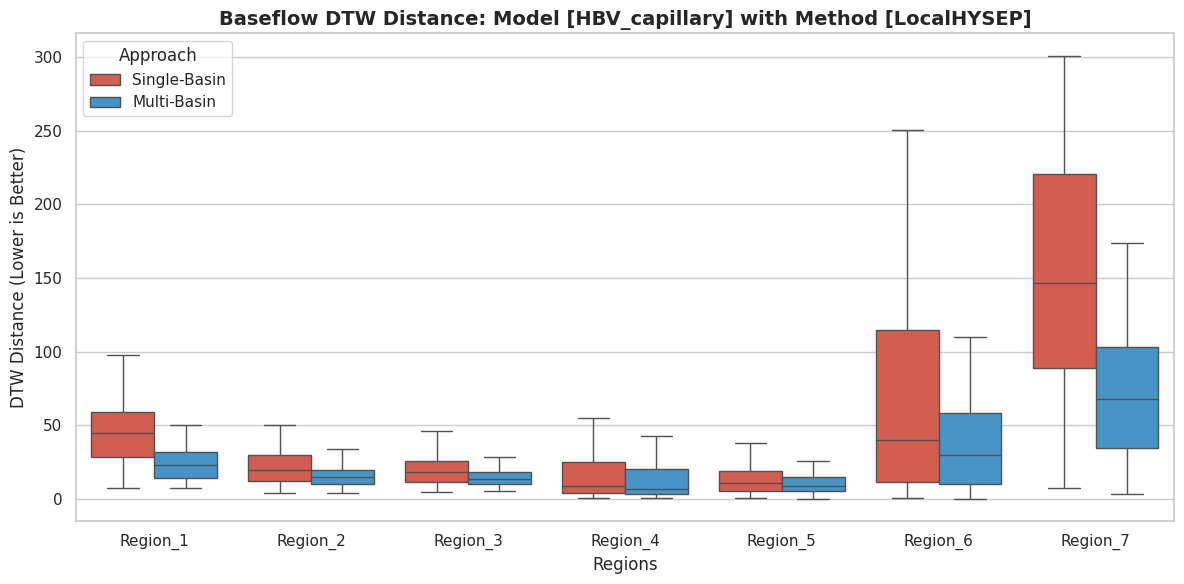

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dtaidistance import dtw

# --- Configuration Lists ---
methods = ["Furey", "USGS", "Eckhardt", "LocalHYSEP"]
models = ["HBV", "marrmot_PRMS", "HBV_capillary"]
regions = ["Region_1", "Region_2", "Region_3", "Region_4", "Region_5", "Region_6", "Region_7"]

BASE_DIR = "/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single"
dyn_map = {
    "HBV": "parBETA_parBETAET_",
    "marrmot_PRMS": "alpha_cgw_scx_tt_",
    "HBV_capillary": "parBETA_parBETAET_parK0_parUZL_",
}

# --- Nested Loop for Methods and Models ---
for method in methods:
    for model in models:
        MULTI_DIR = f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi"
        dyn = dyn_map[model]
        
        model_dir = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999"
        )

        plot_data = []

        for region in regions:
            single_folder = os.path.join(BASE_DIR, region, model_dir)
            multi_folder = os.path.join(MULTI_DIR, region, model_dir)

            try:
                obs_flow = np.load(os.path.join(multi_folder, "baseflow.npy")).squeeze()
                single_flow = np.load(os.path.join(single_folder, "gwflow.npy")).squeeze()
                multi_flow = np.load(os.path.join(multi_folder, "gwflow.npy")).squeeze()
            except FileNotFoundError:
                continue

            nbasins = obs_flow.shape[1]
            for b in range(nbasins):
                s1 = np.ascontiguousarray(obs_flow[:, b], dtype=np.double)
                s2_s = np.ascontiguousarray(single_flow[:, b], dtype=np.double)
                s2_m = np.ascontiguousarray(multi_flow[:, b], dtype=np.double)

                # Single distance calculation
                valid_s = ~(np.isnan(s1) | np.isnan(s2_s))
                if np.sum(valid_s) > 10:
                    d_single = dtw.distance_fast(s1[valid_s], s2_s[valid_s], use_pruning=True)
                    plot_data.append({"Region": region, "Model Type": "Single-Basin", "DTW Distance": d_single})

                # Multi distance calculation
                valid_m = ~(np.isnan(s1) | np.isnan(s2_m))
                if np.sum(valid_m) > 10:
                    d_multi = dtw.distance_fast(s1[valid_m], s2_m[valid_m], use_pruning=True)
                    plot_data.append({"Region": region, "Model Type": "Multi-Basin", "DTW Distance": d_multi})

        if not plot_data:
            print(f"Skipping plot for {method} - {model}: No data found.")
            continue

        df_plot = pd.DataFrame(plot_data)

        # --- Plotting Boxplot ---
        plt.figure(figsize=(12, 6))
        sns.set_theme(style="whitegrid")

        sns.boxplot(
            data=df_plot, 
            x="Region", 
            y="DTW Distance", 
            hue="Model Type", 
            palette={"Single-Basin": "#e74c3c", "Multi-Basin": "#3498db"},
            showfliers=False # Keeps the plot clean of extreme error outliers
        )

        plt.title(f"Baseflow DTW Distance: Model [{model}] with Method [{method}]", fontsize=14, fontweight='bold')
        plt.xlabel("Regions", fontsize=12)
        plt.ylabel("DTW Distance (Lower is Better)", fontsize=12)
        plt.legend(title="Approach")
        plt.tight_layout()

        # Save individual figures automatically for your paper
        plot_filename = f"dtw_box_{model}_{method}.png"
        # plt.savefig(plot_filename, dpi=300)
        print(f"Saved plot: {plot_filename}")
        
        plt.show() # Close figure to free up memory across the large loop